In [8]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Environment working!")

Pandas: 3.1.1
NumPy: 2.5.5
Environment working!


# E-commerce Intelligence: Revenue, Customer Behaviour & Profitability Analytics

## Project Overview

This project aims to analyse e-commerce business performance using Python, Pandas, NumPy, Matplotlib, Seaborn, SQL and Power BI.

### Business Objective
To investigate sales performance, product profitability, customer purchasing behaviour, discount effectiveness and product returns.

### Dataset
Global E-commerce Orders & Returns (2024–2026)

### Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- MySQL
- Power BI

### Project Workflow
1. Data Acquisition
2. Data Audit
3. Data Cleaning
4. Data Integration
5. Exploratory Data Analysis
6. Data Visualisation
7. Power BI Dashboard
8. Business Recommendations

In [9]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import sys
from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All libraries imported successfully!")
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Python version: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.1.1
NumPy version: 2.5.5


In [10]:
# Check the current working directory

print("Current working directory:")
print(os.getcwd())

Current working directory:
c:\Users\user\OneDrive\Desktop\E commerce project\Notebooks


In [11]:
# Define the raw data folder

DATA_PATH = Path("E-commerce Data")
# List expected CSV files

expected_files = [
    "customers.csv",
    "products.csv",
    "orders.csv",
    "order_items.csv",
    "returns.csv"
]

# Check file availability

for file in expected_files:
    file_path = DATA_PATH / file

    if file_path.exists():
        print(f"FOUND: {file}")
    else:
        print(f"MISSING: {file}")

FOUND: customers.csv
FOUND: products.csv
FOUND: orders.csv
FOUND: order_items.csv
FOUND: returns.csv


In [14]:
# Load all five datasets

customers = pd.read_csv( "E-commerce Data/customers.csv")
products = pd.read_csv( "E-commerce Data/products.csv")
orders = pd.read_csv("E-commerce Data/orders.csv")
order_items = pd.read_csv("E-commerce Data/order_items.csv")
returns = pd.read_csv("E-commerce Data/returns.csv")

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [15]:
# Store datasets in a dictionary for convenient inspection

datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Order Items": order_items,
    "Returns": returns
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (3000, 12)
Products: (345, 10)
Orders: (14000, 20)
Order Items: (29671, 11)
Returns: (2433, 15)


In [16]:
# Create an initial dataset inventory

inventory = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()]
})

inventory

,Dataset,Rows,Columns
0,Customers,3000,12
1,Products,345,10
2,Orders,14000,20
3,Order Items,29671,11
4,Returns,2433,15


In [17]:
for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name}")
    print(f"{'='*50}")

    print("Columns:")
    print(df.columns.tolist())


DATASET: Customers
Columns:
['customer_id', 'customer_name', 'country', 'region', 'currency_code', 'signup_date', 'acquisition_channel', 'preferred_device', 'newsletter_opt_in', 'first_order_date', 'lifetime_orders', 'lifetime_spend_usd']

DATASET: Products
Columns:
['product_id', 'product_name', 'category', 'subcategory', 'brand', 'list_price_usd', 'unit_cost_usd', 'weight_kg', 'launch_date', 'is_active']

DATASET: Orders
Columns:
['order_id', 'customer_id', 'order_date', 'order_month', 'sales_channel', 'device_type', 'payment_method', 'shipping_country', 'shipping_region', 'currency_code', 'fx_rate_to_usd', 'items_count', 'gross_amount_local', 'discount_local', 'shipping_fee_local', 'tax_local', 'order_total_local', 'order_total_usd', 'order_status', 'delivery_days']

DATASET: Order Items
Columns:
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_local', 'line_discount_local', 'line_total_local', 'line_total_usd', 'unit_cost_usd', 'line_profit_usd', 'currency_code'

In [18]:
# Generate a preliminary data dictionary

data_dictionary = []

for name, df in datasets.items():

    for column in df.columns:

        data_dictionary.append({
            "Dataset": name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Non-Null Values": df[column].count(),
            "Missing Values": df[column].isnull().sum(),
            "Unique Values": df[column].nunique()
        })

data_dictionary = pd.DataFrame(data_dictionary)

display(data_dictionary)

,Dataset,Column,Data Type,Non-Null Values,Missing Values,Unique Values
0,Customers,customer_id,str,3000,0,3000
1,Customers,customer_name,str,3000,0,597
2,Customers,country,str,3000,0,12
3,Customers,region,str,3000,0,5
4,Customers,currency_code,str,3000,0,10
5,Customers,signup_date,str,3000,0,1133
6,Customers,acquisition_channel,str,3000,0,7
7,Customers,preferred_device,str,3000,0,3
8,Customers,newsletter_opt_in,str,3000,0,2
9,Customers,first_order_date,str,2966,34,844


In [19]:
# Customers with missing first order dates

missing_first_order = customers[
    customers["first_order_date"].isnull()
]

print("Customers without first order date:",
      len(missing_first_order))

print("\nLifetime orders distribution:")

display(
    missing_first_order["lifetime_orders"].value_counts()
)

Customers without first order date: 34

Lifetime orders distribution:


lifetime_orders
0    34
Name: count, dtype: int64

In [20]:
# Orders with missing delivery days

missing_delivery = orders[
    orders["delivery_days"].isnull()
]

print("Orders with missing delivery days:",
      len(missing_delivery))

print("\nOrder status distribution:")

display(
    missing_delivery["order_status"].value_counts()
)

Orders with missing delivery days: 1246

Order status distribution:


order_status
Cancelled     807
Processing    439
Name: count, dtype: int64

In [21]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Total duplicate rows:", df.duplicated().sum())


Customers
Total duplicate rows: 0

Products
Total duplicate rows: 0

Orders
Total duplicate rows: 0

Order Items
Total duplicate rows: 0

Returns
Total duplicate rows: 0


In [22]:
primary_keys = {
    "Customers": ("customers", "customer_id"),
    "Products": ("products", "product_id"),
    "Orders": ("orders", "order_id"),
    "Order Items": ("order_items", "order_item_id"),
    "Returns": ("returns", "return_id")
}

for name, (df_name, column) in primary_keys.items():
    df = datasets[name]

    print(f"\n{name}")
    print("Total records:", len(df))
    print("Unique IDs:", df[column].nunique())
    print("Duplicate IDs:", df[column].duplicated().sum())


Customers
Total records: 3000
Unique IDs: 3000
Duplicate IDs: 0

Products
Total records: 345
Unique IDs: 345
Duplicate IDs: 0

Orders
Total records: 14000
Unique IDs: 14000
Duplicate IDs: 0

Order Items
Total records: 29671
Unique IDs: 29671
Duplicate IDs: 0

Returns
Total records: 2433
Unique IDs: 2433
Duplicate IDs: 0


In [23]:
relationships = [
    ("Orders → Customers", orders, "customer_id", customers, "customer_id"),
    ("Order Items → Orders", order_items, "order_id", orders, "order_id"),
    ("Order Items → Products", order_items, "product_id", products, "product_id"),
    ("Returns → Orders", returns, "order_id", orders, "order_id"),
    ("Returns → Order Items", returns, "order_item_id", order_items, "order_item_id"),
    ("Returns → Products", returns, "product_id", products, "product_id"),
    ("Returns → Customers", returns, "customer_id", customers, "customer_id")
]

for name, child_df, child_col, parent_df, parent_col in relationships:

    unmatched = child_df.loc[
        ~child_df[child_col].isin(parent_df[parent_col]),
        child_col
    ]

    print(f"\n{name}")
    print("Unmatched records:", len(unmatched))


Orders → Customers
Unmatched records: 0

Order Items → Orders
Unmatched records: 0

Order Items → Products
Unmatched records: 0

Returns → Orders
Unmatched records: 0

Returns → Order Items
Unmatched records: 0

Returns → Products
Unmatched records: 0

Returns → Customers
Unmatched records: 0


In [24]:
categorical_columns = [
    "country",
    "region",
    "acquisition_channel",
    "preferred_device",
    "newsletter_opt_in"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    display(customers[col].value_counts(dropna=False))


--- country ---


country
United States           662
United Kingdom          310
India                   286
Germany                 272
United Arab Emirates    220
France                  200
Saudi Arabia            198
Australia               185
Canada                  180
Japan                   177
Brazil                  174
Spain                   136
Name: count, dtype: int64


--- region ---


region
Europe           918
North America    842
Asia-Pacific     648
Middle East      418
Latin America    174
Name: count, dtype: int64


--- acquisition_channel ---


acquisition_channel
Organic Search    676
Paid Social       569
Paid Search       522
Email             424
Direct            347
Affiliate         244
Marketplace       218
Name: count, dtype: int64


--- preferred_device ---


preferred_device
Mobile     1708
Desktop    1028
Tablet      264
Name: count, dtype: int64


--- newsletter_opt_in ---


newsletter_opt_in
No     1653
Yes    1347
Name: count, dtype: int64

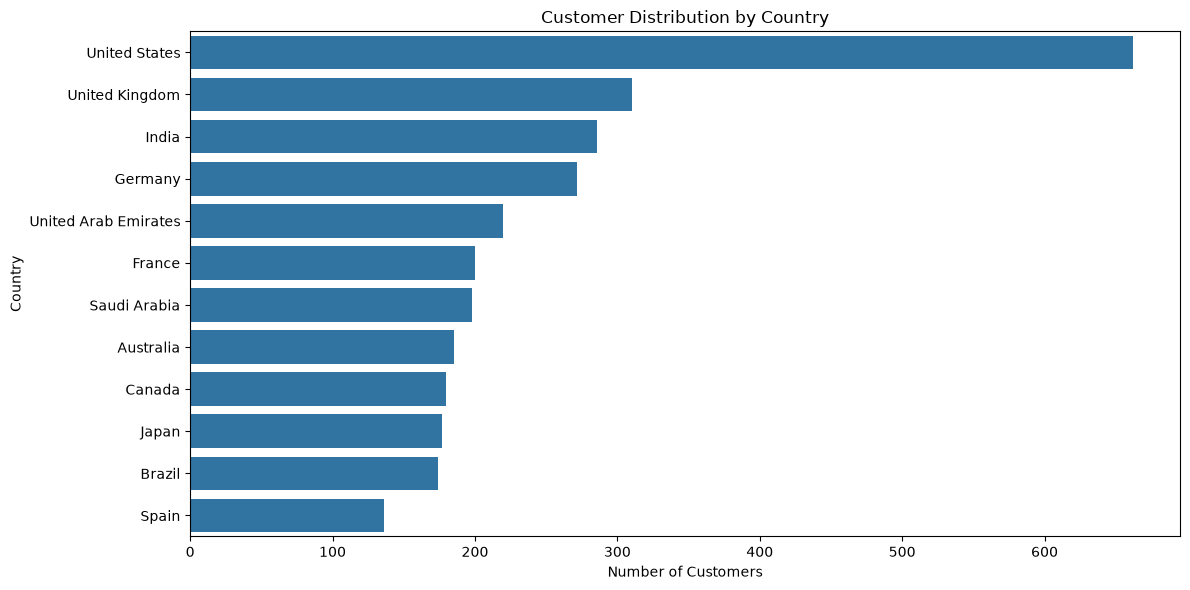

In [29]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=customers,
    y="country",
    order=customers["country"].value_counts().index
)

plt.title("Customer Distribution by Country")
plt.xlabel("Number of Customers")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [30]:
display(customers["region"].value_counts(dropna=False))

region
Europe           918
North America    842
Asia-Pacific     648
Middle East      418
Latin America    174
Name: count, dtype: int64

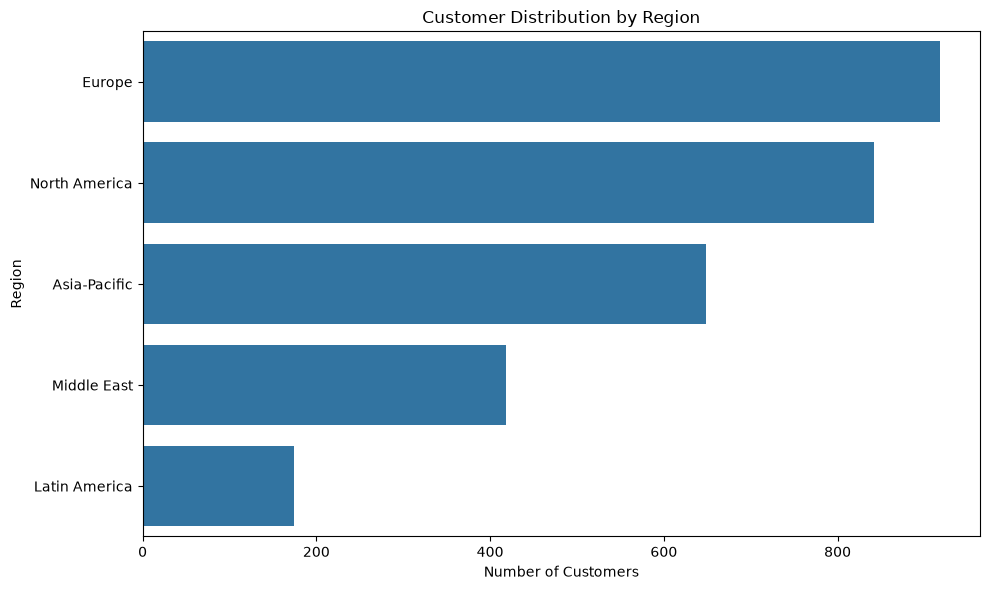

In [34]:
region_counts = customers["region"].value_counts()

region_percentages = customers["region"].value_counts(normalize=True) * 100

plt.figure(figsize=(10, 6))

sns.barplot(
    x=region_counts.values,
    y=region_counts.index
)

plt.title("Customer Distribution by Region")
plt.xlabel("Number of Customers")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

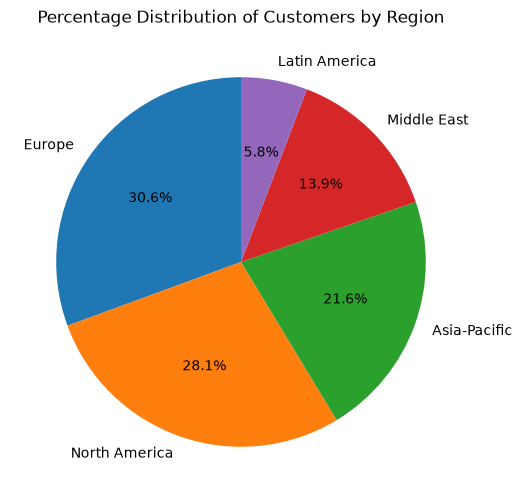

In [38]:
plt.figure(figsize=(9, 6))

plt.pie(
    region_counts,
    labels=region_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Customers by Region")
plt.show()

In [39]:
display(customers["acquisition_channel"].value_counts(dropna=False))

acquisition_channel
Organic Search    676
Paid Social       569
Paid Search       522
Email             424
Direct            347
Affiliate         244
Marketplace       218
Name: count, dtype: int64

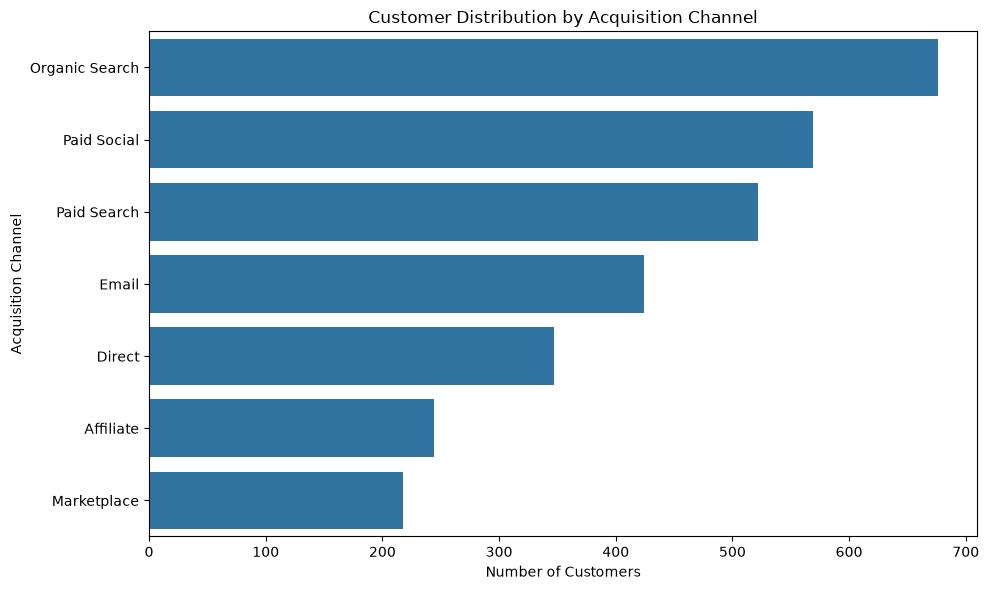

In [42]:
channel_counts = customers["acquisition_channel"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=channel_counts.values,
    y=channel_counts.index
)

plt.title("Customer Distribution by Acquisition Channel")
plt.xlabel("Number of Customers")
plt.ylabel("Acquisition Channel")

plt.tight_layout()
plt.show()

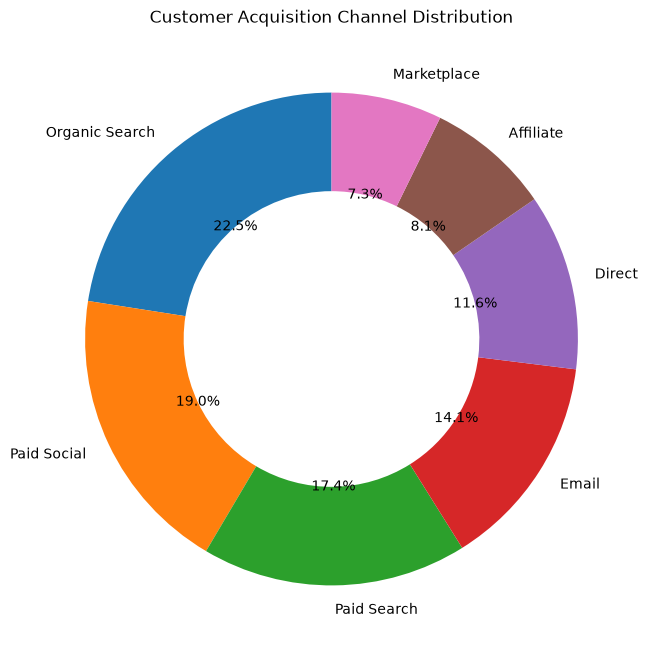

In [45]:
plt.figure(figsize=(8, 8))

plt.pie(
    channel_counts,
    labels=channel_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Customer Acquisition Channel Distribution")

plt.show()

In [46]:
display(customers["preferred_device"].value_counts(dropna=False))

preferred_device
Mobile     1708
Desktop    1028
Tablet      264
Name: count, dtype: int64

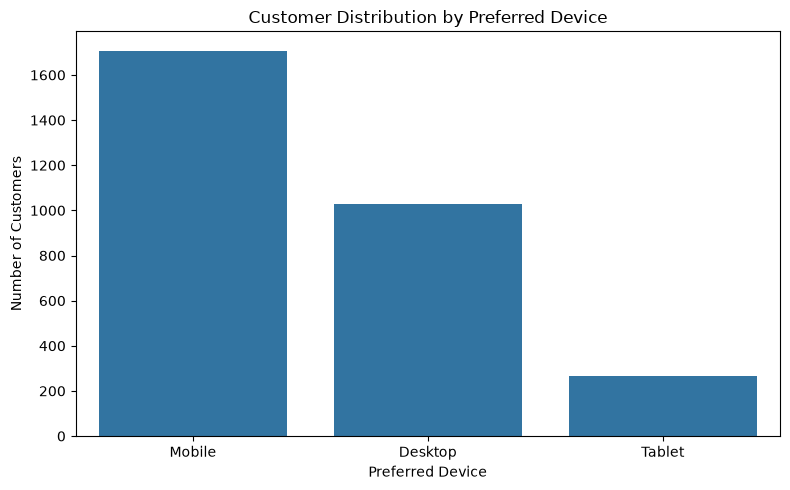

In [48]:
device_counts = customers["preferred_device"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=device_counts.index,
    y=device_counts.values
)

plt.title("Customer Distribution by Preferred Device")
plt.xlabel("Preferred Device")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

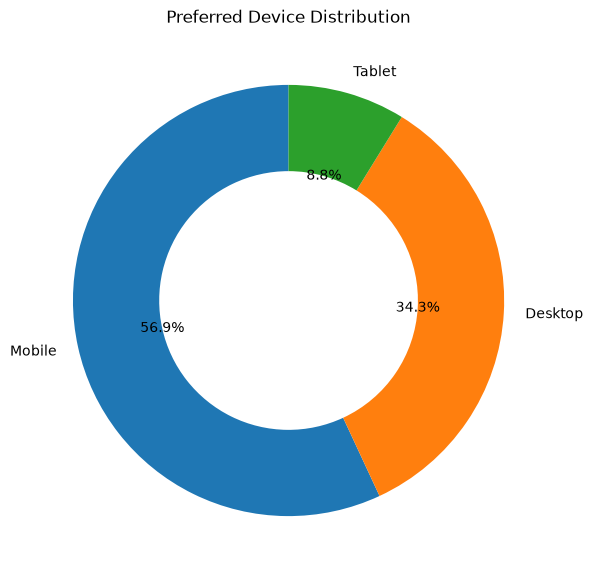

In [50]:
plt.figure(figsize=(7, 7))

plt.pie(
    device_counts,
    labels=device_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Preferred Device Distribution")

plt.show()

In [51]:
display(customers["newsletter_opt_in"].value_counts(dropna=False))


newsletter_opt_in
No     1653
Yes    1347
Name: count, dtype: int64

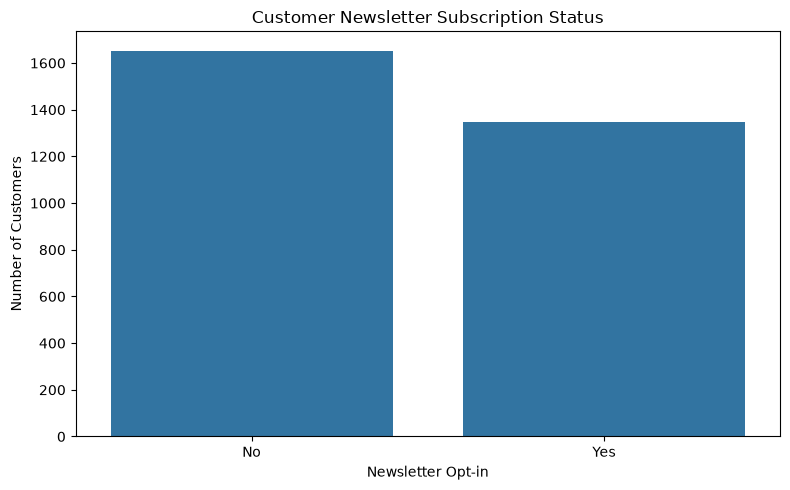

In [52]:
newsletter_counts = customers["newsletter_opt_in"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=newsletter_counts.index,
    y=newsletter_counts.values
)

plt.title("Customer Newsletter Subscription Status")
plt.xlabel("Newsletter Opt-in")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

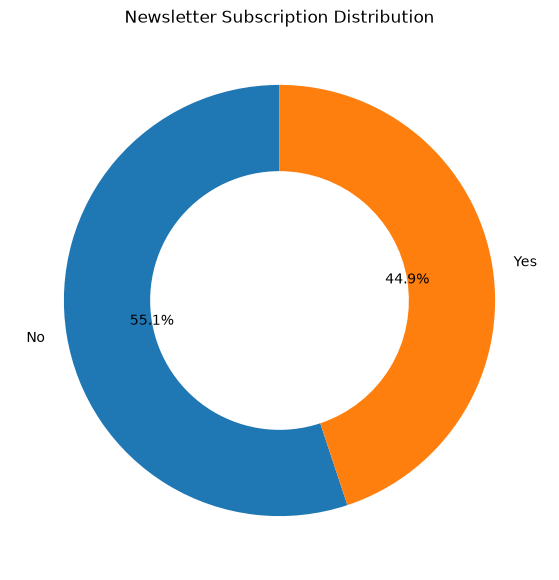

In [53]:
plt.figure(figsize=(7, 7))

plt.pie(
    newsletter_counts,
    labels=newsletter_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Newsletter Subscription Distribution")

plt.show()

In [54]:
product_categorical_columns = [
    "category",
    "subcategory",
    "brand",
    "is_active"
]

for col in product_categorical_columns:
    print(f"\n--- {col} ---")
    display(products[col].value_counts(dropna=False))


--- category ---


category
Apparel           90
Electronics       75
Home & Kitchen    45
Beauty            45
Sports            45
Toys & Games      45
Name: count, dtype: int64


--- subcategory ---


subcategory
Footwear         25
Cameras          25
Dresses          23
Jackets          23
Wearables        21
T-Shirts         19
Fragrance        18
Cycling          17
Board Games      17
Headphones       16
Skincare         16
Plush            16
Outdoor          15
Accessories      13
Storage          13
Fitness          13
Textiles         12
Building Sets    12
Haircare         11
Cookware         10
Lighting         10
Name: count, dtype: int64


--- brand ---


brand
Marlowe       44
Brightfold    37
Northline     36
Tanuki        36
Vantia        35
Auralis       35
Corvid        34
Solstice      33
Ferrix        28
Kestrel       27
Name: count, dtype: int64


--- is_active ---


is_active
Yes    323
No      22
Name: count, dtype: int64

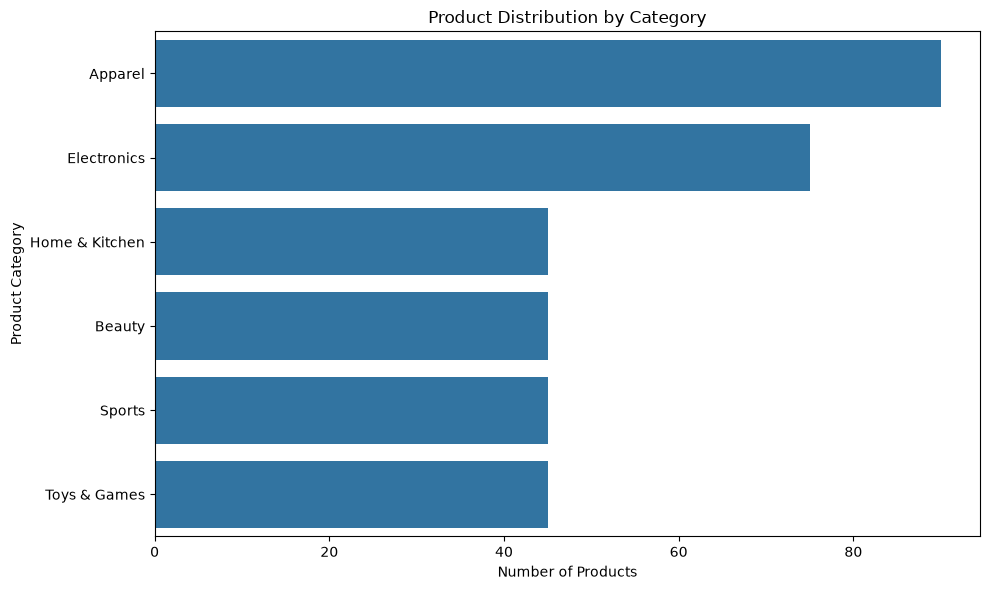

In [55]:
category_counts = products["category"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Product Distribution by Category")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

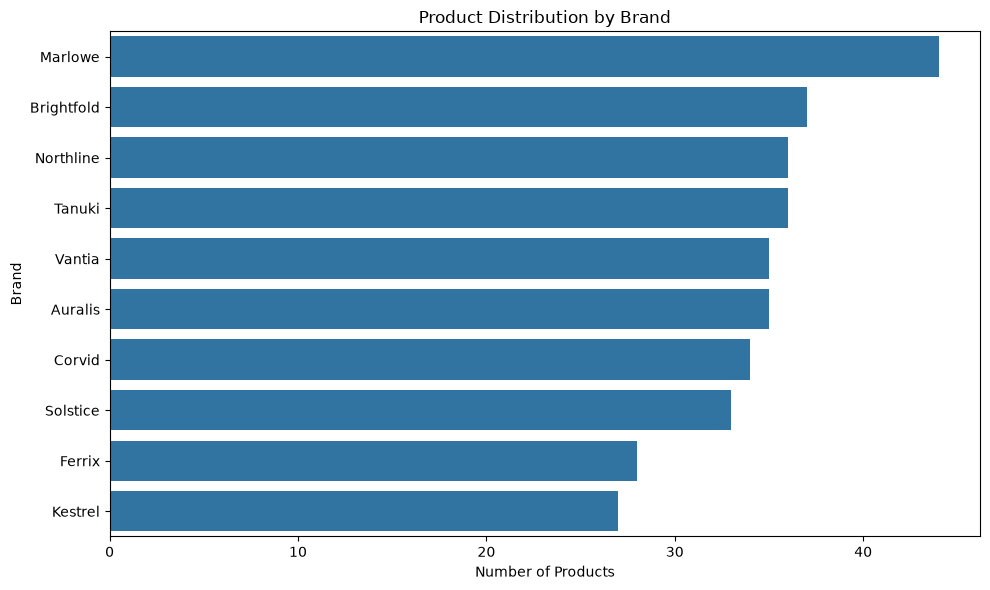

In [56]:
brand_counts = products["brand"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=brand_counts.values,
    y=brand_counts.index
)

plt.title("Product Distribution by Brand")
plt.xlabel("Number of Products")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

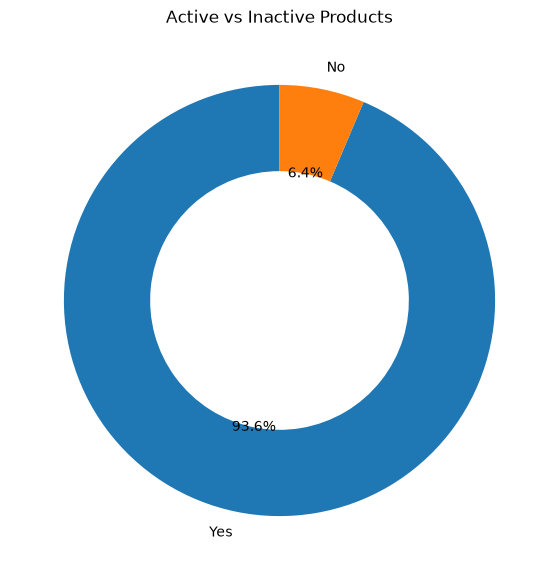

In [57]:
active_counts = products["is_active"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    active_counts,
    labels=active_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Active vs Inactive Products")
plt.show()

In [58]:
product_numeric = [
    "list_price_usd",
    "unit_cost_usd",
    "weight_kg"
]

display(products[product_numeric].describe().T)

,count,mean,std,min,25%,50%,75%,max
list_price_usd,345.0,181.028116,185.927646,10.40,67.99,111.39,204.12,898.66
unit_cost_usd,345.0,111.736290,138.530841,4.12,32.00,54.40,125.72,649.92
weight_kg,345.0,3.063507,1.744620,0.10,1.53,3.06,4.55,5.99


In [59]:
print("Missing values in product columns:")

display(products[product_numeric].isnull().sum())

Missing values in product columns:


list_price_usd    0
unit_cost_usd     0
weight_kg         0
dtype: int64

In [60]:
for col in product_numeric:

    print(f"\n--- {col} ---")

    print("Zero values:", (products[col] == 0).sum())
    print("Negative values:", (products[col] < 0).sum())


--- list_price_usd ---
Zero values: 0
Negative values: 0

--- unit_cost_usd ---
Zero values: 0
Negative values: 0

--- weight_kg ---
Zero values: 0
Negative values: 0


In [61]:
print("Zero weights:", (products["weight_kg"] == 0).sum())
print("Negative weights:", (products["weight_kg"] < 0).sum())

Zero weights: 0
Negative weights: 0


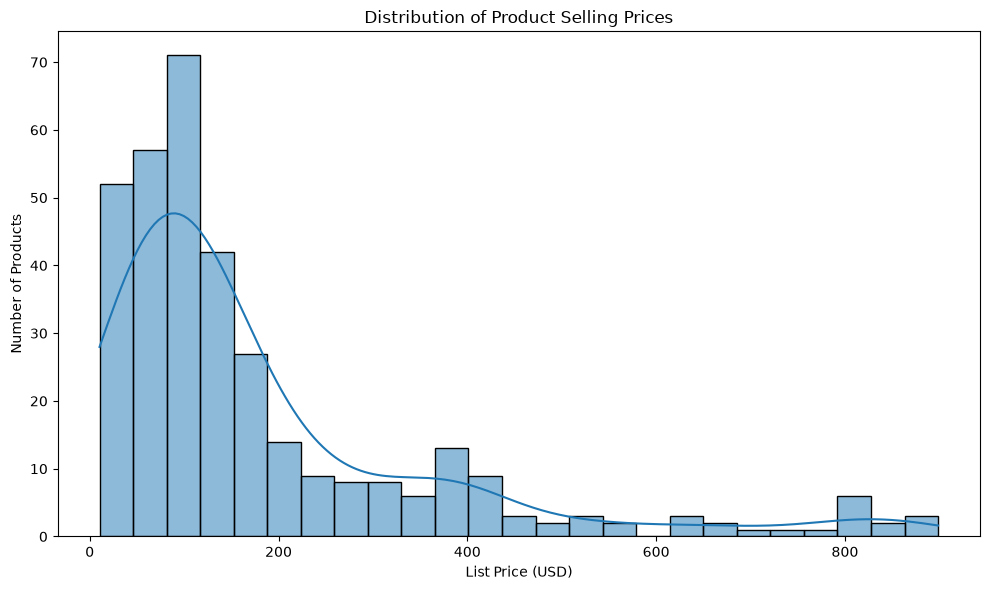

In [62]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=products,
    x="list_price_usd",
    bins=25,
    kde=True
)

plt.title("Distribution of Product Selling Prices")
plt.xlabel("List Price (USD)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

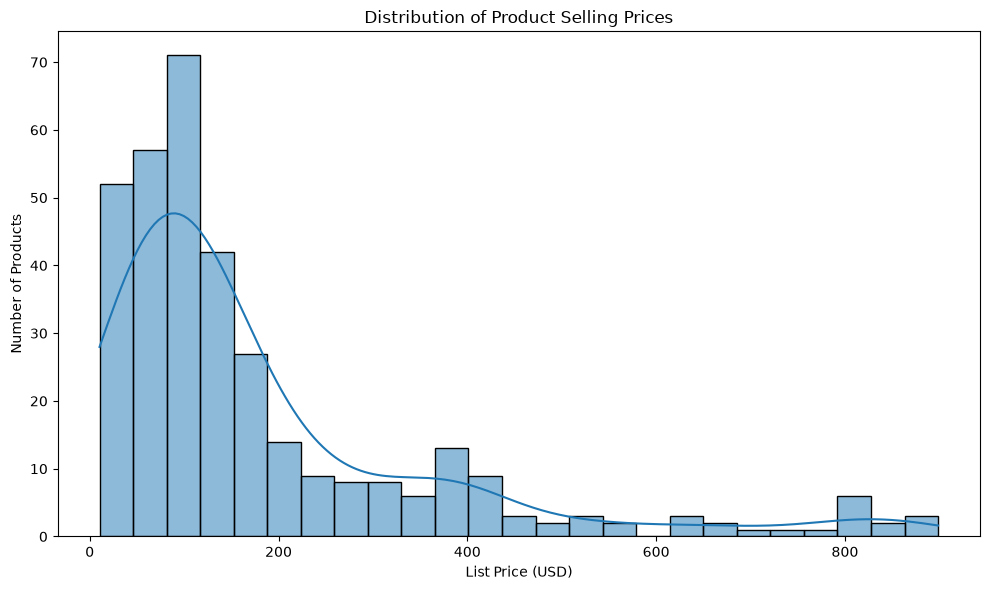

In [63]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=products,
    x="list_price_usd",
    bins=25,
    kde=True
)

plt.title("Distribution of Product Selling Prices")
plt.xlabel("List Price (USD)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

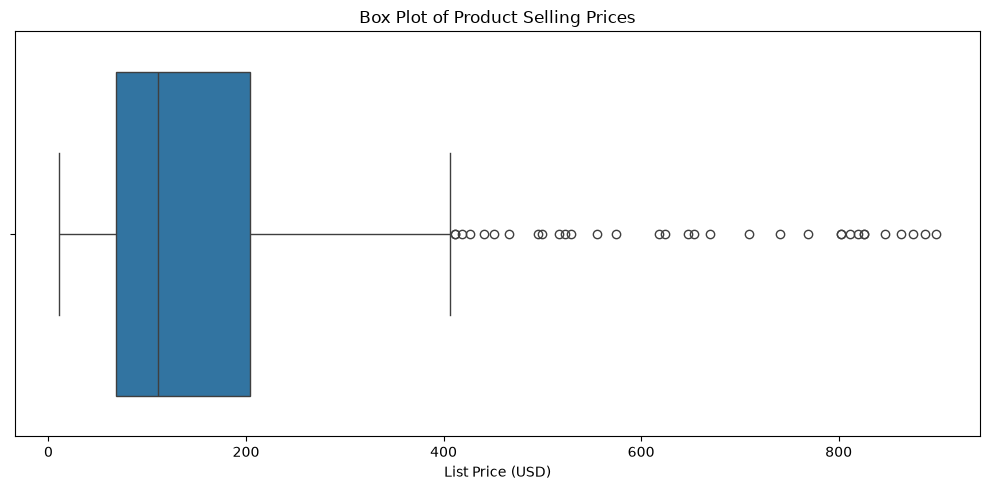

In [64]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=products,
    x="list_price_usd"
)

plt.title("Box Plot of Product Selling Prices")
plt.xlabel("List Price (USD)")

plt.tight_layout()
plt.show()

In [65]:
Q1 = products["list_price_usd"].quantile(0.25)
Q3 = products["list_price_usd"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

price_outliers = products[
    (products["list_price_usd"] < lower_bound) |
    (products["list_price_usd"] > upper_bound)
]

print("\nNumber of potential outliers:", len(price_outliers))

display(
    price_outliers[
        ["product_name", "category", "brand", "list_price_usd"]
    ].sort_values("list_price_usd", ascending=False)
)

Q1: 67.99
Q3: 204.12
IQR: 136.13
Lower Bound: -136.20499999999998
Upper Bound: 408.315

Number of potential outliers: 33


,product_name,category,brand,list_price_usd
96,Brightfold Wearable 0097,Electronics,Marlowe,898.66
117,Corvid Headphone 0118,Electronics,Ferrix,887.69
132,Ferrix Headphone 0133,Electronics,Vantia,875.59
92,Marlowe Wearable 0093,Electronics,Kestrel,862.84
122,Solstice Wearable 0123,Electronics,Solstice,847.11
91,Marlowe Camera 0092,Electronics,Kestrel,825.70
131,Auralis Camera 0132,Electronics,Auralis,825.34
111,Vantia Headphone 0112,Electronics,Marlowe,819.88
93,Kestrel Camera 0094,Electronics,Marlowe,811.56
151,Marlowe Camera 0152,Electronics,Marlowe,802.50


In [66]:
outlier_summary = (
    price_outliers
    .groupby("category")
    .agg(
        outlier_count=("product_id", "count"),
        average_price=("list_price_usd", "mean"),
        highest_price=("list_price_usd", "max")
    )
    .sort_values("outlier_count", ascending=False)
)

display(outlier_summary)

,outlier_count,average_price,highest_price
category,,,
Electronics,31,663.939355,898.66
Sports,2,414.895000,418.66


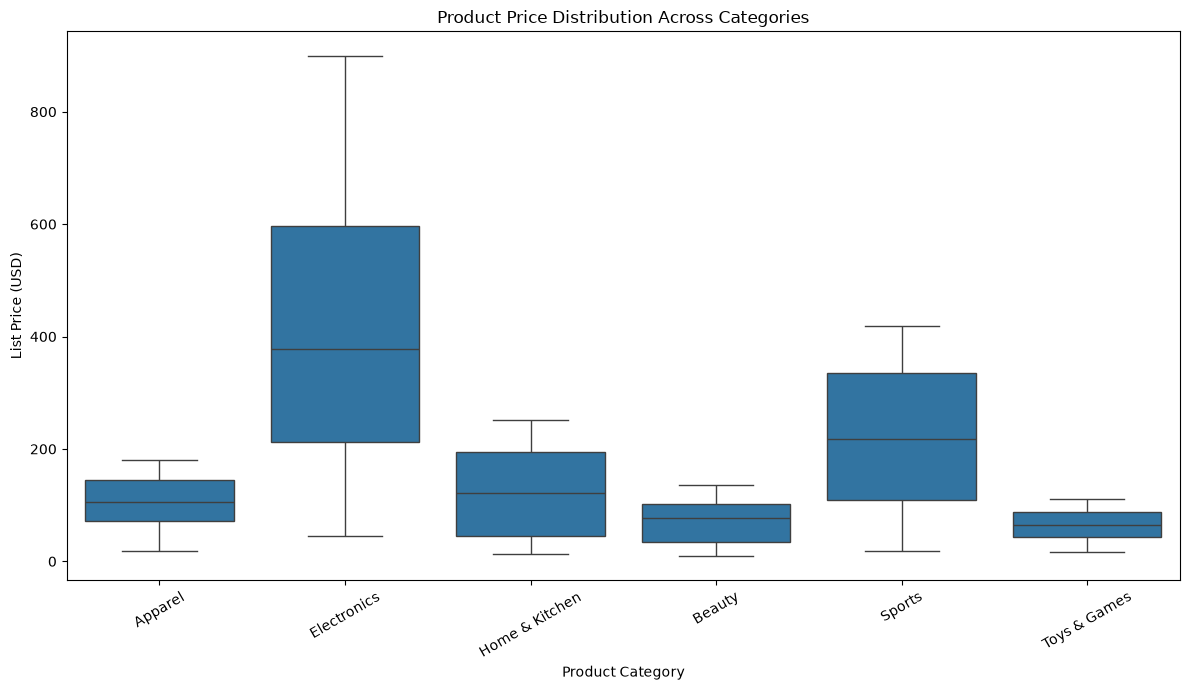

In [67]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=products,
    x="category",
    y="list_price_usd"
)

plt.title("Product Price Distribution Across Categories")
plt.xlabel("Product Category")
plt.ylabel("List Price (USD)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

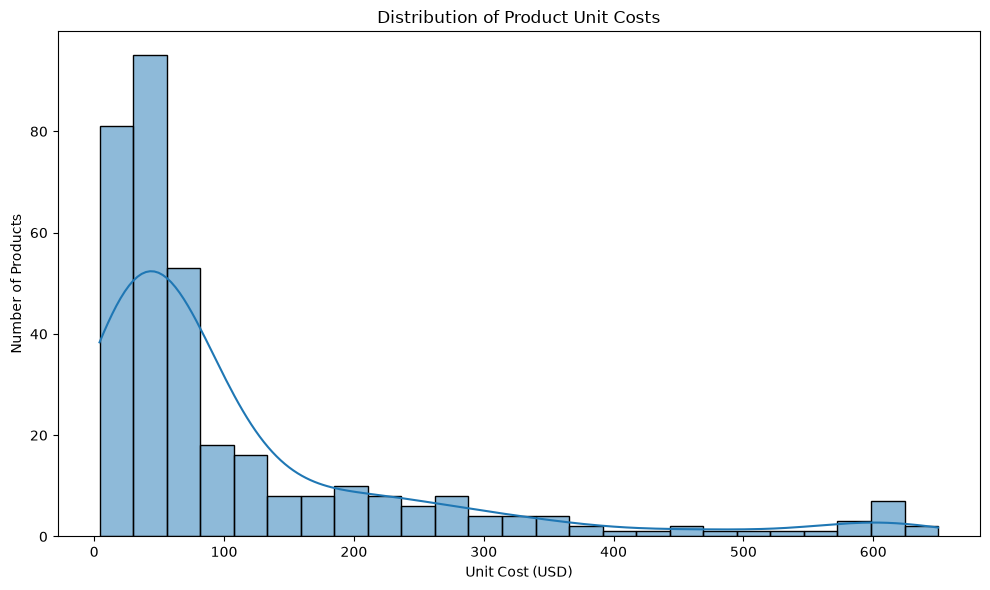

In [68]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=products,
    x="unit_cost_usd",
    bins=25,
    kde=True
)

plt.title("Distribution of Product Unit Costs")
plt.xlabel("Unit Cost (USD)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

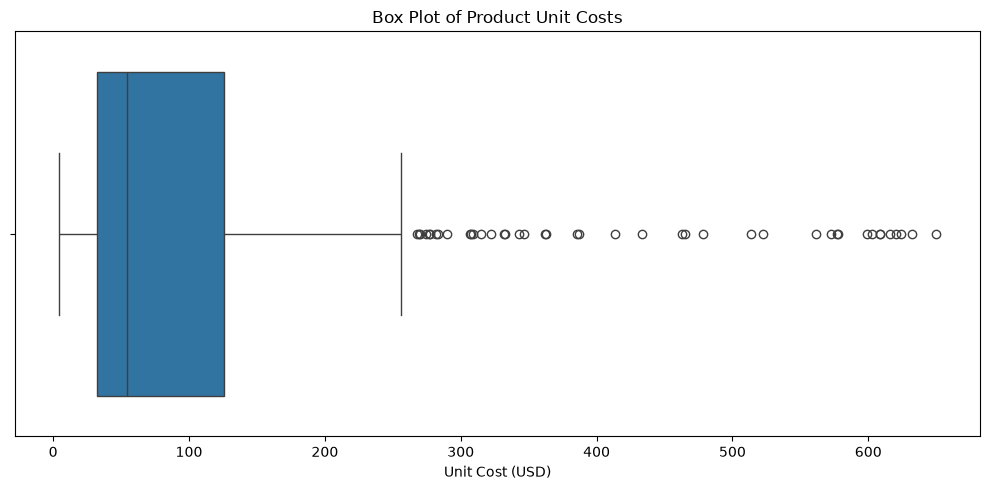

In [69]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=products,
    x="unit_cost_usd"
)

plt.title("Box Plot of Product Unit Costs")
plt.xlabel("Unit Cost (USD)")

plt.tight_layout()
plt.show()

In [70]:
Q1_cost = products["unit_cost_usd"].quantile(0.25)
Q3_cost = products["unit_cost_usd"].quantile(0.75)

IQR_cost = Q3_cost - Q1_cost

lower_cost = Q1_cost - 1.5 * IQR_cost
upper_cost = Q3_cost + 1.5 * IQR_cost

print("Q1:", Q1_cost)
print("Q3:", Q3_cost)
print("IQR:", IQR_cost)
print("Lower Bound:", lower_cost)
print("Upper Bound:", upper_cost)

cost_outliers = products[
    (products["unit_cost_usd"] < lower_cost) |
    (products["unit_cost_usd"] > upper_cost)
]

print("\nNumber of potential cost outliers:", len(cost_outliers))

display(
    cost_outliers[
        ["product_name", "category", "brand",
         "list_price_usd", "unit_cost_usd"]
    ].sort_values("unit_cost_usd", ascending=False)
)

Q1: 32.0
Q3: 125.72
IQR: 93.72
Lower Bound: -108.57999999999998
Upper Bound: 266.29999999999995

Number of potential cost outliers: 42


,product_name,category,brand,list_price_usd,unit_cost_usd
122,Solstice Wearable 0123,Electronics,Solstice,847.11,649.92
91,Marlowe Camera 0092,Electronics,Kestrel,825.70,632.31
151,Marlowe Camera 0152,Electronics,Marlowe,802.50,624.02
111,Vantia Headphone 0112,Electronics,Marlowe,819.88,620.70
132,Ferrix Headphone 0133,Electronics,Vantia,875.59,615.91
158,Northline Wearable 0159,Electronics,Brightfold,802.07,608.72
96,Brightfold Wearable 0097,Electronics,Marlowe,898.66,608.47
117,Corvid Headphone 0118,Electronics,Ferrix,887.69,602.62
131,Auralis Camera 0132,Electronics,Auralis,825.34,598.83
104,Corvid Wearable 0105,Electronics,Ferrix,768.73,577.60


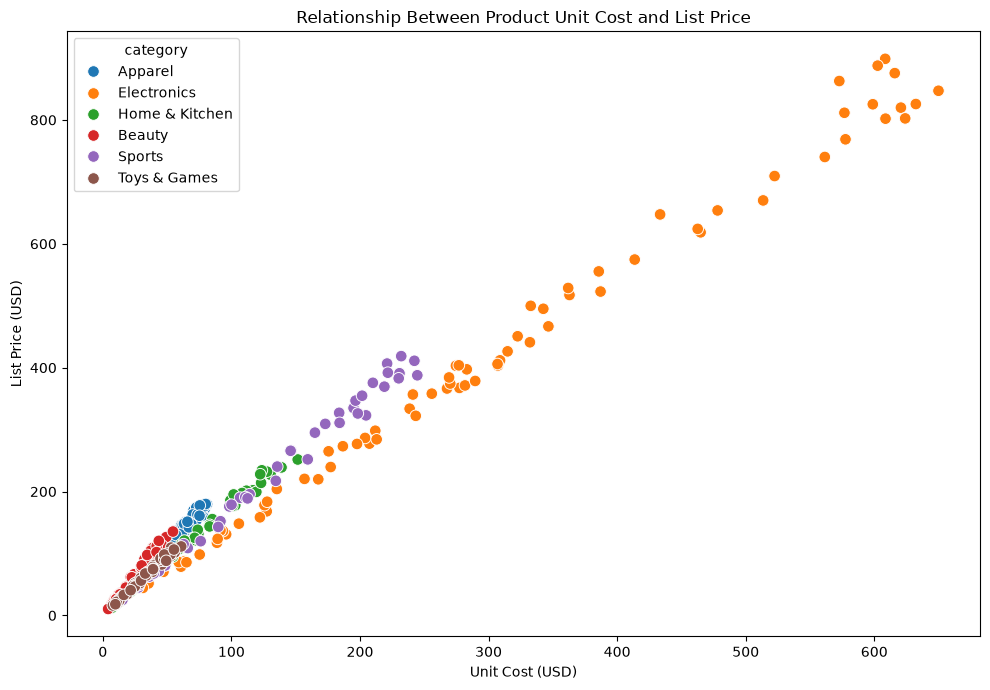

In [71]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=products,
    x="unit_cost_usd",
    y="list_price_usd",
    hue="category",
    s=70
)

plt.title("Relationship Between Product Unit Cost and List Price")
plt.xlabel("Unit Cost (USD)")
plt.ylabel("List Price (USD)")

plt.tight_layout()
plt.show()

In [72]:
product_analysis = products.copy()

product_analysis["gross_profit_per_unit"] = (
    product_analysis["list_price_usd"]
    - product_analysis["unit_cost_usd"]
)

product_analysis["gross_margin_pct"] = (
    product_analysis["gross_profit_per_unit"]
    / product_analysis["list_price_usd"]
) * 100

display(
    product_analysis[
        ["product_name", "category", "brand",
         "list_price_usd", "unit_cost_usd",
         "gross_profit_per_unit", "gross_margin_pct"]
    ].head(10)
)

,product_name,category,brand,list_price_usd,unit_cost_usd,gross_profit_per_unit,gross_margin_pct
0,Northline Footwear 0001,Apparel,Northline,105.82,51.08,54.74,51.729352
1,Solstice T-Shirt 0002,Apparel,Marlowe,90.07,42.16,47.91,53.191962
2,Ferrix Footwear 0003,Apparel,Brightfold,127.19,56.37,70.82,55.680478
3,Vantia Dresse 0004,Apparel,Kestrel,82.41,34.30,48.11,58.378838
4,Brightfold Footwear 0005,Apparel,Northline,28.14,13.37,14.77,52.487562
5,Corvid Footwear 0006,Apparel,Vantia,135.56,64.59,70.97,52.353202
6,Northline Jacket 0007,Apparel,Ferrix,110.39,53.59,56.80,51.453936
7,Vantia Footwear 0008,Apparel,Kestrel,110.53,48.85,61.68,55.803854
8,Tanuki T-Shirt 0009,Apparel,Marlowe,117.71,53.56,64.15,54.498343
9,Tanuki T-Shirt 0010,Apparel,Tanuki,93.60,42.08,51.52,55.042735


In [73]:
display(
    product_analysis[
        ["gross_profit_per_unit", "gross_margin_pct"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
gross_profit_per_unit,345.0,69.291826,51.898359,5.350000,33.070000,56.430000,89.410000,290.190000
gross_margin_pct,345.0,45.957967,11.754507,22.240498,39.794257,46.599442,55.610098,64.936115


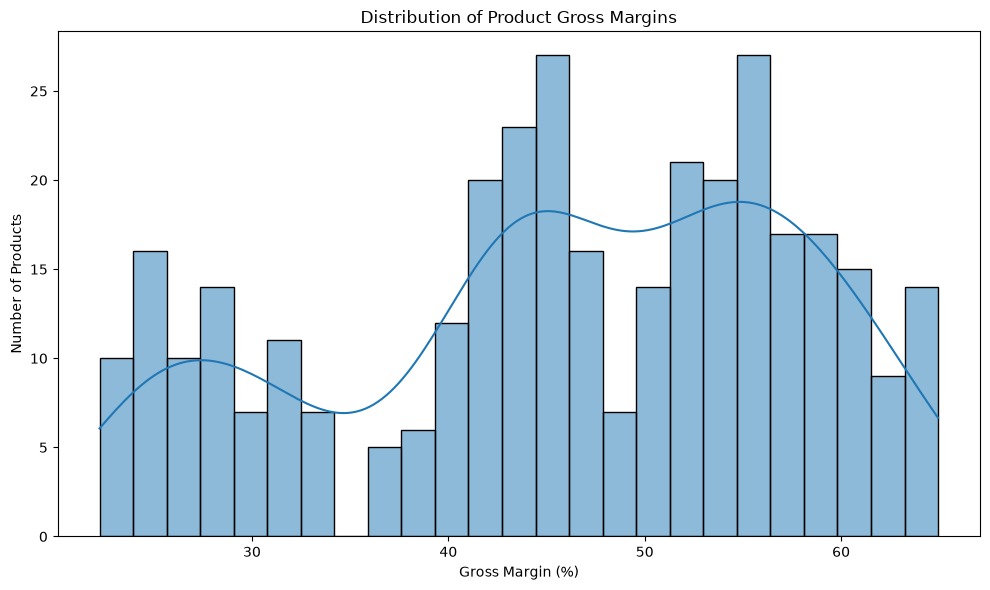

In [74]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=product_analysis,
    x="gross_margin_pct",
    bins=25,
    kde=True
)

plt.title("Distribution of Product Gross Margins")
plt.xlabel("Gross Margin (%)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [75]:
category_margin = (
    product_analysis
    .groupby("category")
    .agg(
        average_margin=("gross_margin_pct", "mean"),
        median_margin=("gross_margin_pct", "median"),
        average_profit=("gross_profit_per_unit", "mean"),
        product_count=("product_id", "count")
    )
    .sort_values("average_margin", ascending=False)
)

display(category_margin.round(2))

,average_margin,median_margin,average_profit,product_count
category,,,,
Beauty,61.92,61.52,44.74,45
Apparel,55.19,55.48,58.09,90
Toys & Games,48.25,48.00,30.93,45
Home & Kitchen,43.83,43.46,54.14,45
Sports,41.78,42.02,94.58,45
Electronics,27.72,27.75,114.40,75


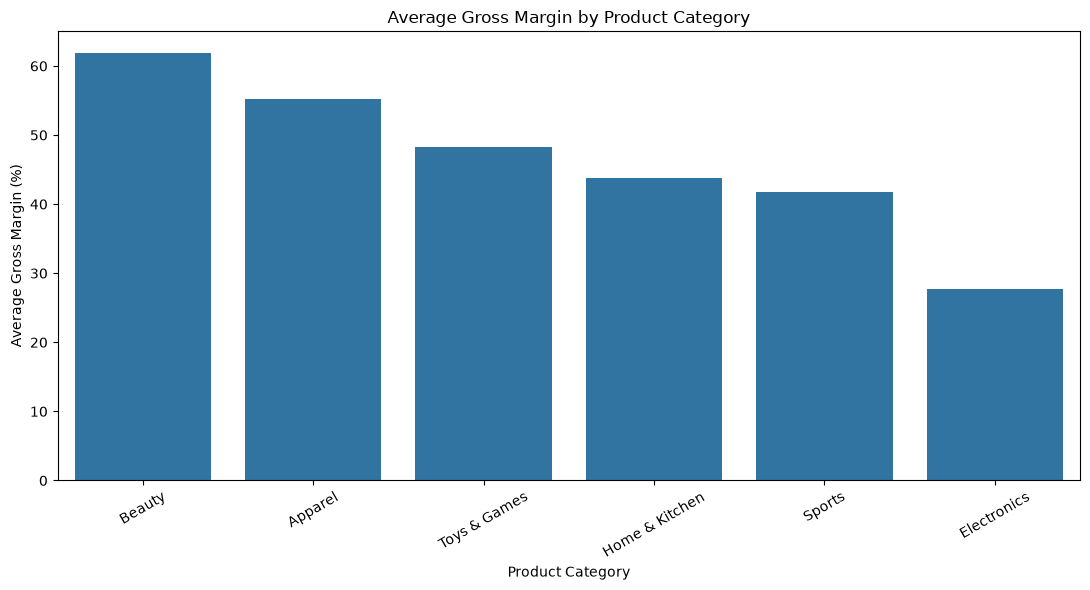

In [76]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_margin.reset_index(),
    x="category",
    y="average_margin"
)

plt.title("Average Gross Margin by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Gross Margin (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

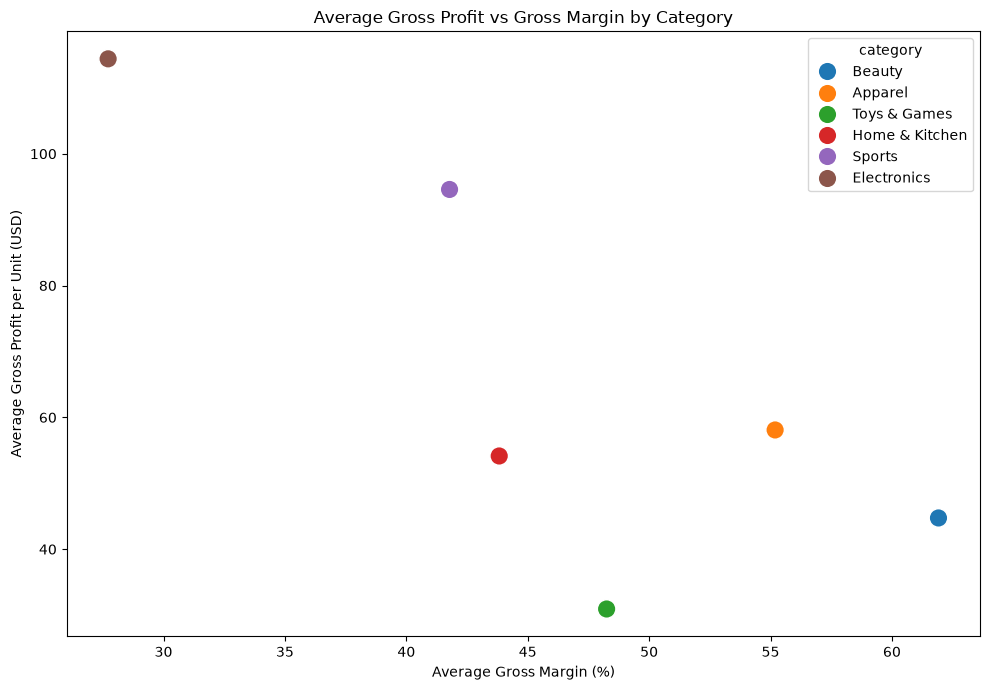

In [77]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=category_margin.reset_index(),
    x="average_margin",
    y="average_profit",
    hue="category",
    s=180
)

plt.title("Average Gross Profit vs Gross Margin by Category")
plt.xlabel("Average Gross Margin (%)")
plt.ylabel("Average Gross Profit per Unit (USD)")

plt.tight_layout()
plt.show()

In [78]:
brand_margin = (
    product_analysis
    .groupby("brand")
    .agg(
        average_margin=("gross_margin_pct", "mean"),
        median_margin=("gross_margin_pct", "median"),
        average_profit=("gross_profit_per_unit", "mean"),
        product_count=("product_id", "count")
    )
    .sort_values("average_margin", ascending=False)
)

display(brand_margin.round(2))

,average_margin,median_margin,average_profit,product_count
brand,,,,
Northline,49.55,51.48,55.65,36
Vantia,47.51,52.25,69.25,35
Corvid,46.98,46.31,55.43,34
Ferrix,46.39,45.42,77.40,28
Brightfold,46.26,46.77,64.20,37
Solstice,45.76,45.30,64.21,33
Auralis,45.38,45.18,78.39,35
Kestrel,45.04,45.19,78.79,27
Tanuki,43.83,45.92,69.11,36


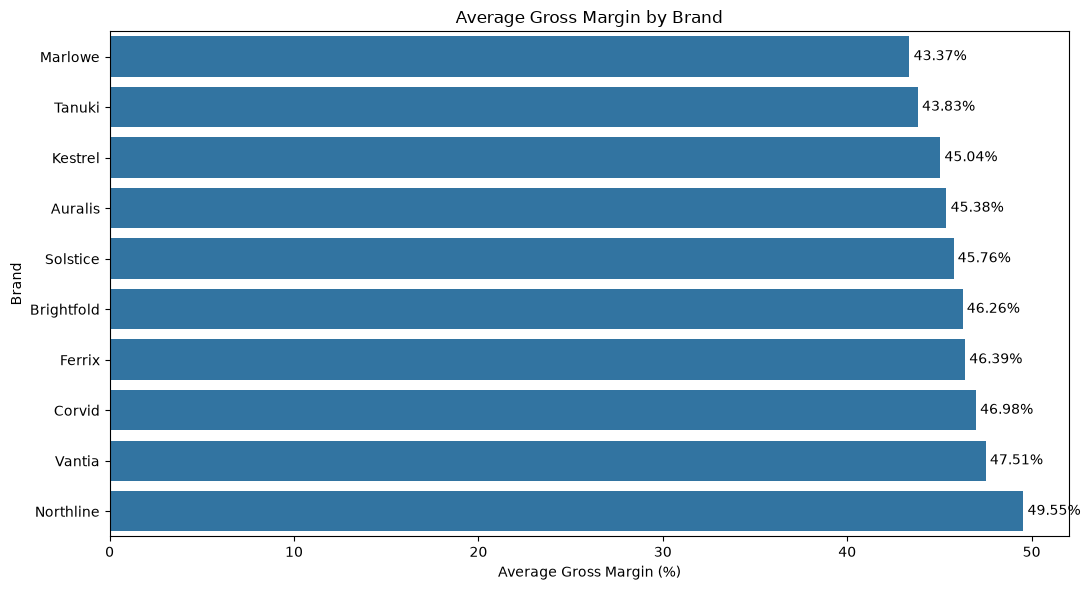

In [80]:
plt.figure(figsize=(11, 6))

brand_plot = brand_margin.reset_index().sort_values(
    "average_margin",
    ascending=True
)

sns.barplot(
    data=brand_plot,
    x="average_margin",
    y="brand"
)

plt.title("Average Gross Margin by Brand")
plt.xlabel("Average Gross Margin (%)")
plt.ylabel("Brand")

plt.tight_layout()
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.2f%%', padding=3)

plt.tight_layout()
plt.show()

In [82]:
# Top 10 products by gross profit per unit

top_profit_products = products.sort_values(
    by="gross_profit_per_unit",
    ascending=False
)

display(
    top_profit_products[
        [
            "product_name",
            "category",
            "brand",
            "list_price_usd",
            "unit_cost_usd",
            "gross_profit_per_unit",
            "gross_margin_pct"
        ]
    ].head(10)
)

KeyError: 'gross_profit_per_unit'

In [83]:
# Calculate gross profit per unit
products["gross_profit_per_unit"] = (
    products["list_price_usd"] - products["unit_cost_usd"]
)

# Calculate gross margin percentage
products["gross_margin_pct"] = (
    products["gross_profit_per_unit"] / products["list_price_usd"]
) * 100

In [84]:
display(
    products[
        [
            "product_name",
            "list_price_usd",
            "unit_cost_usd",
            "gross_profit_per_unit",
            "gross_margin_pct"
        ]
    ].head()
)

,product_name,list_price_usd,unit_cost_usd,gross_profit_per_unit,gross_margin_pct
0,Northline Footwear 0001,105.82,51.08,54.74,51.729352
1,Solstice T-Shirt 0002,90.07,42.16,47.91,53.191962
2,Ferrix Footwear 0003,127.19,56.37,70.82,55.680478
3,Vantia Dresse 0004,82.41,34.30,48.11,58.378838
4,Brightfold Footwear 0005,28.14,13.37,14.77,52.487562


In [85]:
top_profit_products = products.sort_values(
    by="gross_profit_per_unit",
    ascending=False
)

display(
    top_profit_products[
        [
            "product_name",
            "category",
            "brand",
            "list_price_usd",
            "unit_cost_usd",
            "gross_profit_per_unit",
            "gross_margin_pct"
        ]
    ].head(10)
)

,product_name,category,brand,list_price_usd,unit_cost_usd,gross_profit_per_unit,gross_margin_pct
96,Brightfold Wearable 0097,Electronics,Marlowe,898.66,608.47,290.19,32.291412
92,Marlowe Wearable 0093,Electronics,Kestrel,862.84,572.79,290.05,33.615734
117,Corvid Headphone 0118,Electronics,Ferrix,887.69,602.62,285.07,32.113688
132,Ferrix Headphone 0133,Electronics,Vantia,875.59,615.91,259.68,29.657717
93,Kestrel Camera 0094,Electronics,Marlowe,811.56,576.76,234.80,28.931934
131,Auralis Camera 0132,Electronics,Auralis,825.34,598.83,226.51,27.444447
138,Solstice Wearable 0139,Electronics,Auralis,647.46,433.41,214.05,33.059957
111,Vantia Headphone 0112,Electronics,Marlowe,819.88,620.70,199.18,24.293799
122,Solstice Wearable 0123,Electronics,Solstice,847.11,649.92,197.19,23.277969
91,Marlowe Camera 0092,Electronics,Kestrel,825.70,632.31,193.39,23.421339


In [86]:
top_margin_products = products.sort_values(
    by="gross_margin_pct",
    ascending=False
)

display(
    top_margin_products[
        [
            "product_name",
            "category",
            "brand",
            "list_price_usd",
            "unit_cost_usd",
            "gross_profit_per_unit",
            "gross_margin_pct"
        ]
    ].head(10)
)

,product_name,category,brand,list_price_usd,unit_cost_usd,gross_profit_per_unit,gross_margin_pct
239,Northline Fragrance 0240,Beauty,Northline,61.83,21.68,40.15,64.936115
222,Auralis Skincare 0223,Beauty,Northline,25.70,9.02,16.68,64.902724
211,Brightfold Skincare 0212,Beauty,Northline,26.81,9.41,17.40,64.901156
253,Corvid Fragrance 0254,Beauty,Ferrix,97.72,34.48,63.24,64.715514
232,Tanuki Skincare 0233,Beauty,Marlowe,109.31,38.75,70.56,64.550361
231,Kestrel Fragrance 0232,Beauty,Tanuki,96.45,34.33,62.12,64.406428
238,Marlowe Haircare 0239,Beauty,Tanuki,104.24,37.15,67.09,64.361090
240,Auralis Fragrance 0241,Beauty,Brightfold,90.62,32.31,58.31,64.345619
235,Tanuki Skincare 0236,Beauty,Vantia,108.96,38.93,70.03,64.271292
248,Corvid Fragrance 0249,Beauty,Tanuki,120.36,43.53,76.83,63.833500


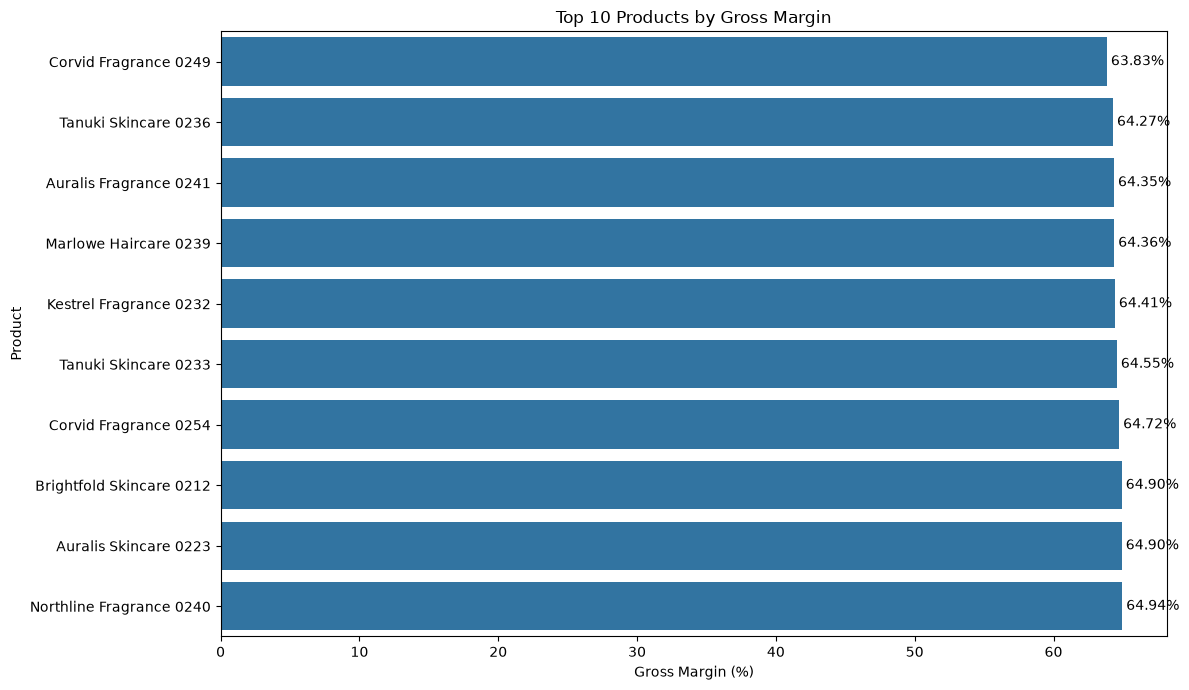

In [87]:
plt.figure(figsize=(12, 7))

top_10_margin = top_margin_products.head(10).sort_values(
    by="gross_margin_pct",
    ascending=True
)

ax = sns.barplot(
    data=top_10_margin,
    x="gross_margin_pct",
    y="product_name"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Top 10 Products by Gross Margin")
plt.xlabel("Gross Margin (%)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [88]:
bottom_10_margin = products.sort_values(
    by="gross_margin_pct",
    ascending=True
).head(10)

bottom_10_margin[
    ["product_name", "category", "brand",
     "list_price_usd", "unit_cost_usd",
     "gross_profit_per_unit", "gross_margin_pct"]
]

,product_name,category,brand,list_price_usd,unit_cost_usd,gross_profit_per_unit,gross_margin_pct
151,Marlowe Camera 0152,Electronics,Marlowe,802.50,624.02,178.48,22.240498
125,Brightfold Wearable 0126,Electronics,Solstice,78.75,60.77,17.98,22.831746
103,Tanuki Camera 0104,Electronics,Tanuki,158.39,122.17,36.22,22.867605
122,Solstice Wearable 0123,Electronics,Solstice,847.11,649.92,197.19,23.277969
124,Marlowe Wearable 0125,Electronics,Brightfold,670.06,513.55,156.51,23.357610
102,Corvid Camera 0103,Electronics,Tanuki,98.35,75.34,23.01,23.396035
91,Marlowe Camera 0092,Electronics,Kestrel,825.70,632.31,193.39,23.421339
164,Corvid Accessorie 0165,Electronics,Marlowe,378.56,289.61,88.95,23.496936
123,Kestrel Headphone 0124,Electronics,Marlowe,219.81,167.55,52.26,23.775078
129,Tanuki Camera 0130,Electronics,Marlowe,403.51,307.26,96.25,23.853188


In [89]:
category_margin = (
    products.groupby("category")
    .agg(
        average_margin=("gross_margin_pct", "mean"),
        median_margin=("gross_margin_pct", "median"),
        average_profit=("gross_profit_per_unit", "mean"),
        product_count=("product_id", "count")
    )
    .sort_values(by="average_margin", ascending=False)
)

category_margin

,average_margin,median_margin,average_profit,product_count
category,,,,
Beauty,61.916109,61.521655,44.737778,45
Apparel,55.187943,55.476678,58.089444,90
Toys & Games,48.248772,48.002632,30.925778,45
Home & Kitchen,43.825384,43.460601,54.142667,45
Sports,41.780022,42.016851,94.583333,45
Electronics,27.718945,27.753054,114.401333,75


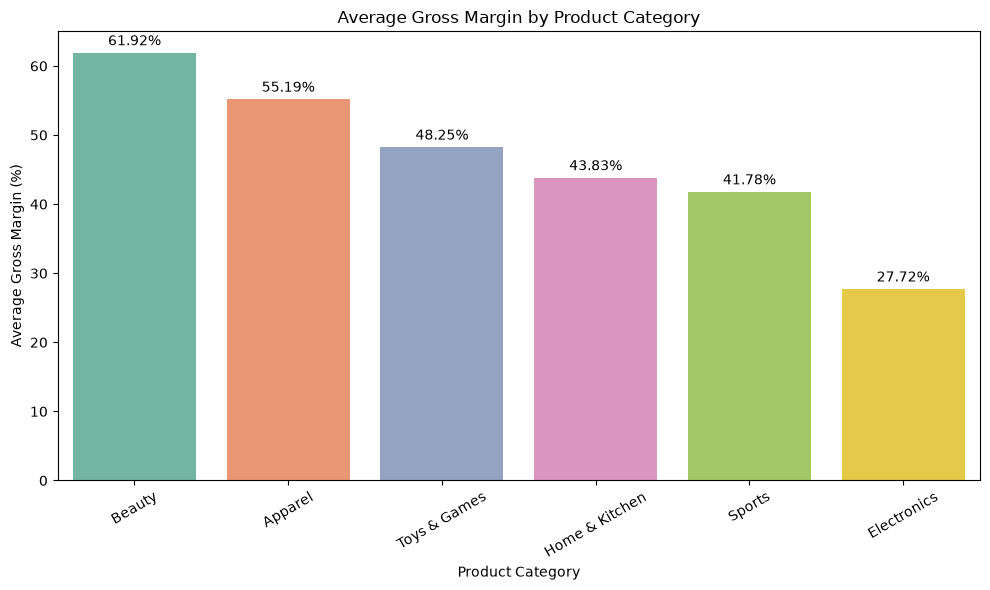

In [90]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=category_margin.reset_index(),
    x="category",
    y="average_margin",
    hue="category",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Average Gross Margin by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Gross Margin (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

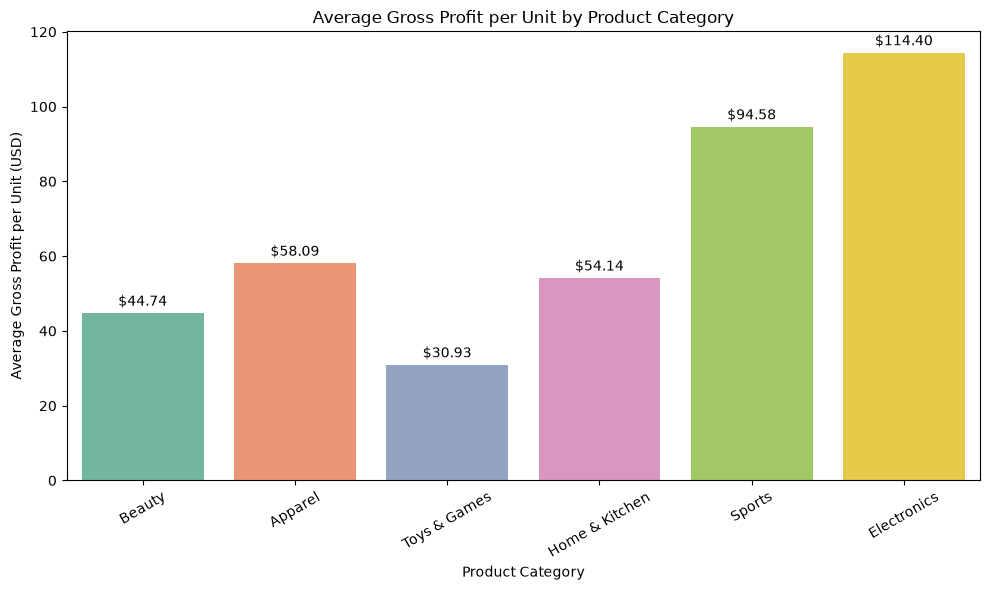

In [91]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=category_margin.reset_index(),
    x="category",
    y="average_profit",
    hue="category",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="$%.2f", padding=3)

plt.title("Average Gross Profit per Unit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Gross Profit per Unit (USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [93]:
brand_margin = (
    products.groupby("brand")
    .agg(
        average_margin=("gross_margin_pct", "mean"),
        median_margin=("gross_margin_pct", "median"),
        average_profit=("gross_profit_per_unit", "mean"),
        product_count=("product_id", "count")
    )
    .sort_values(by="average_margin", ascending=False)
)

brand_margin

,average_margin,median_margin,average_profit,product_count
brand,,,,
Northline,49.551609,51.479356,55.654722,36
Vantia,47.511127,52.245345,69.246571,35
Corvid,46.978446,46.307950,55.426176,34
Ferrix,46.391715,45.416591,77.395000,28
Brightfold,46.256577,46.765068,64.198108,37
Solstice,45.764099,45.300296,64.212121,33
Auralis,45.381002,45.183888,78.394000,35
Kestrel,45.044015,45.185607,78.793704,27
Tanuki,43.830226,45.918311,69.109167,36


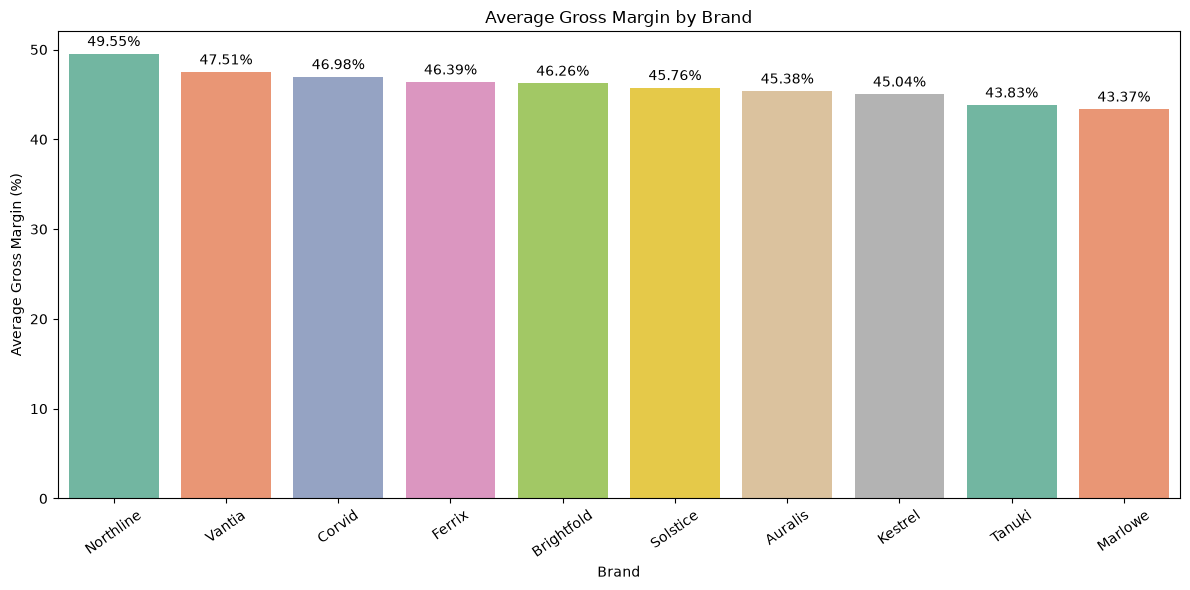

In [94]:
plt.figure(figsize=(12, 6))

brand_plot = brand_margin.reset_index()

ax = sns.barplot(
    data=brand_plot,
    x="brand",
    y="average_margin",
    hue="brand",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Average Gross Margin by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Gross Margin (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

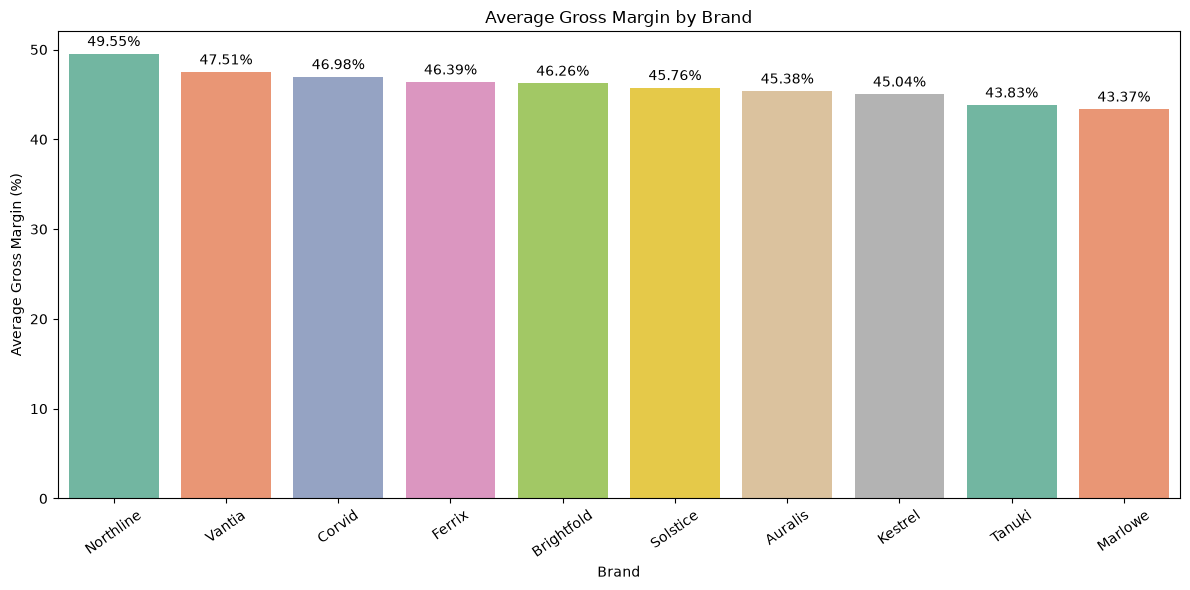

In [95]:
plt.figure(figsize=(12, 6))

brand_plot = brand_margin.reset_index()

ax = sns.barplot(
    data=brand_plot,
    x="brand",
    y="average_margin",
    hue="brand",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Average Gross Margin by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Gross Margin (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [96]:
orders["order_status"].value_counts(dropna=False)

order_status
Delivered     12030
Cancelled       807
Shipped         724
Processing      439
Name: count, dtype: int64

In [97]:
orders["order_status"].value_counts(normalize=True) * 100

order_status
Delivered     85.928571
Cancelled      5.764286
Shipped        5.171429
Processing     3.135714
Name: proportion, dtype: float64

In [98]:
orders.groupby("order_status")["delivery_days"].agg(
    total_orders="count",
    average_delivery_days="mean"
)

,total_orders,average_delivery_days
order_status,,
Cancelled,0,NaN
Delivered,12030,6.478304
Processing,0,NaN
Shipped,724,6.635359


In [99]:
orders.groupby("order_status").agg(
    total_orders=("order_id", "count"),
    missing_delivery_days=("delivery_days", lambda x: x.isna().sum()),
    average_delivery_days=("delivery_days", "mean")
)

,total_orders,missing_delivery_days,average_delivery_days
order_status,,,
Cancelled,807,807,NaN
Delivered,12030,0,6.478304
Processing,439,439,NaN
Shipped,724,0,6.635359


In [100]:
order_items[
    [
        "quantity",
        "unit_price_local",
        "line_discount_local",
        "line_total_local",
        "line_total_usd",
        "unit_cost_usd",
        "line_profit_usd"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,29671.0,1.408244,0.752436,1.00,1.00,1.00,2.000,4.00
unit_price_local,29671.0,3251.629780,10923.677315,8.22,88.09,191.09,652.300,135697.66
line_discount_local,29671.0,306.528461,2391.679488,0.00,0.00,0.00,16.175,88880.36
line_total_local,29671.0,4375.021626,17437.624313,6.35,95.95,247.56,832.790,528856.36
line_total_usd,29671.0,238.832468,313.442585,6.78,71.58,131.50,284.320,3594.65
unit_cost_usd,29671.0,111.081130,137.593390,4.12,31.76,54.40,123.670,649.92
line_profit_usd,29671.0,81.168720,90.047789,-266.14,27.82,54.36,100.040,1160.77


In [101]:
negative_profit = order_items[
    order_items["line_profit_usd"] < 0
]

print("Negative-profit records:", len(negative_profit))

negative_profit[
    [
        "order_id",
        "product_id",
        "quantity",
        "line_total_usd",
        "unit_cost_usd",
        "line_profit_usd"
    ]
].head(10)

Negative-profit records: 484


,order_id,product_id,quantity,line_total_usd,unit_cost_usd,line_profit_usd
48,ORD-000019,PRD-0112,1,601.24,620.70,-19.46
173,ORD-000081,PRD-0147,1,410.38,413.66,-3.28
344,ORD-000167,PRD-0120,1,219.15,243.37,-24.22
351,ORD-000170,PRD-0111,1,60.62,63.71,-3.09
407,ORD-000199,PRD-0120,2,432.08,243.37,-54.66
412,ORD-000201,PRD-0103,1,65.44,75.34,-9.90
431,ORD-000209,PRD-0102,1,194.82,211.88,-17.06
468,ORD-000224,PRD-0159,1,570.22,608.72,-38.50
472,ORD-000226,PRD-0123,1,614.66,649.92,-35.26
572,ORD-000269,PRD-0096,1,359.32,362.94,-3.62


In [103]:
order_items["calculated_profit"] = (
    order_items["line_total_usd"]
    - (order_items["unit_cost_usd"] * order_items["quantity"])
)

order_items[
    [
        "quantity",
        "line_total_usd",
        "unit_cost_usd",
        "line_profit_usd",
        "calculated_profit"
    ]
].head(10)

,quantity,line_total_usd,unit_cost_usd,line_profit_usd,calculated_profit
0,1,42.78,18.99,23.79,23.79
1,1,96.79,53.60,43.19,43.19
2,1,75.23,39.08,36.15,36.15
3,2,1379.76,632.31,115.14,115.14
4,1,47.74,35.15,12.59,12.59
5,1,82.32,45.85,36.47,36.47
6,3,190.48,28.17,105.97,105.97
7,2,1725.68,572.79,580.10,580.10
8,1,195.35,101.71,93.64,93.64
9,1,80.87,47.88,32.99,32.99


In [104]:
(
    order_items["calculated_profit"]
    - order_items["line_profit_usd"]
).describe()

count    2.967100e+04
mean     5.055441e-06
std      2.247900e-04
min     -3.410605e-13
25%     -3.552714e-15
50%      0.000000e+00
75%      3.552714e-15
max      1.000000e-02
dtype: float64

In [105]:
difference = (
    order_items["calculated_profit"]
    - order_items["line_profit_usd"]
)

print("Maximum absolute difference:", difference.abs().max())
print("Number of mismatches:", (difference.abs() > 0.01).sum())

Maximum absolute difference: 0.010000000000047748
Number of mismatches: 2


In [106]:
mismatches = order_items[
    difference.abs() > 0.01
]

mismatches[
    [
        "order_item_id",
        "quantity",
        "line_total_usd",
        "unit_cost_usd",
        "line_profit_usd",
        "calculated_profit"
    ]
]

,order_item_id,quantity,line_total_usd,unit_cost_usd,line_profit_usd,calculated_profit
11647,ITM-011648,1,23.53,16.39,7.13,7.14
18284,ITM-018285,2,1430.63,608.47,213.68,213.69


In [107]:
negative_profit = order_items[
    order_items["calculated_profit"] < 0
]

print("Loss-making order items:", len(negative_profit))

print(
    "Percentage:",
    round(len(negative_profit) / len(order_items) * 100, 2),
    "%"
)

Loss-making order items: 484
Percentage: 1.63 %


In [108]:
loss_by_product = (
    order_items[order_items["calculated_profit"] < 0]
    .groupby("product_id")
    .agg(
        loss_making_items=("order_item_id", "count"),
        total_loss=("calculated_profit", "sum")
    )
    .sort_values("total_loss")
)

loss_by_product.head(10)

,loss_making_items,total_loss
product_id,,
PRD-0112,16,-1219.91
PRD-0123,12,-1038.85
PRD-0092,9,-687.45
PRD-0152,10,-620.66
PRD-0125,10,-556.92
PRD-0110,13,-457.26
PRD-0122,9,-437.97
PRD-0159,8,-420.15
PRD-0153,16,-410.43


In [109]:
loss_product_details = (
    loss_by_product
    .reset_index()
    .merge(
        products[
            [
                "product_id",
                "product_name",
                "category",
                "brand",
                "list_price_usd",
                "unit_cost_usd"
            ]
        ],
        on="product_id",
        how="left"
    )
    .sort_values("total_loss")
)

loss_product_details.head(10)

,product_id,loss_making_items,total_loss,product_name,category,brand,list_price_usd,unit_cost_usd
0,PRD-0112,16,-1219.91,Vantia Headphone 0112,Electronics,Marlowe,819.88,620.70
1,PRD-0123,12,-1038.85,Solstice Wearable 0123,Electronics,Solstice,847.11,649.92
2,PRD-0092,9,-687.45,Marlowe Camera 0092,Electronics,Kestrel,825.70,632.31
3,PRD-0152,10,-620.66,Marlowe Camera 0152,Electronics,Marlowe,802.50,624.02
4,PRD-0125,10,-556.92,Marlowe Wearable 0125,Electronics,Brightfold,670.06,513.55
5,PRD-0110,13,-457.26,Tanuki Wearable 0110,Electronics,Vantia,709.44,522.45
6,PRD-0122,9,-437.97,Ferrix Headphone 0122,Electronics,Tanuki,740.20,561.49
7,PRD-0159,8,-420.15,Northline Wearable 0159,Electronics,Brightfold,802.07,608.72
8,PRD-0153,16,-410.43,Ferrix Accessorie 0153,Electronics,Kestrel,618.53,464.92
9,PRD-0120,15,-407.35,Northline Accessorie 0120,Electronics,Tanuki,322.28,243.37


In [110]:
product_112 = order_items[
    order_items["product_id"] == "PRD-0112"
].copy()

product_112[
    [
        "quantity",
        "unit_price_local",
        "line_discount_local",
        "line_total_usd",
        "unit_cost_usd",
        "calculated_profit"
    ]
].head(20)

,quantity,unit_price_local,line_discount_local,line_total_usd,unit_cost_usd,calculated_profit
48,1,754.29,201.15,601.24,620.7,-19.46
603,1,819.88,0.00,819.88,620.7,199.18
1008,1,68214.02,0.00,819.88,620.7,199.18
1564,3,68214.02,61001.14,1726.45,620.7,-135.65
2679,2,1115.04,0.00,1639.76,620.7,398.36
3464,1,754.29,0.00,819.88,620.7,199.18
3828,3,819.88,689.40,1770.24,620.7,-91.86
4394,2,754.29,0.00,1639.76,620.7,398.36
4483,1,3074.55,979.93,558.57,620.7,-62.13
4620,2,1246.22,329.73,1422.84,620.7,181.44


In [112]:
product_112_check = product_112.merge(
    orders[
        [
            "order_id",
            "currency_code",
            "fx_rate_to_usd"
        ]
    ],
    on="order_id",
    how="left"
)

product_112_check[
    [
        "order_id",
        "currency_code",
        "fx_rate_to_usd",
        "unit_price_local",
        "line_discount_local",
        "line_total_usd",
        "unit_cost_usd",
        "calculated_profit"
    ]
].head(20)

KeyError: "['currency_code'] not in index"

In [113]:
print(product_112_check.columns.tolist())

['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_local', 'line_discount_local', 'line_total_local', 'line_total_usd', 'unit_cost_usd', 'line_profit_usd', 'currency_code_x', 'calculated_profit', 'currency_code_y', 'fx_rate_to_usd']


In [116]:
product_112_check = product_112.merge(
    orders[
        [
            "order_id",
            "currency_code",
            "fx_rate_to_usd"
        ]
    ].rename(columns={"currency_code": "order_currency"}),
    on="order_id",
    how="left"
)

In [117]:
product_112_check[
    [
        "order_id",
        "currency_code",
        "order_currency",
        "fx_rate_to_usd",
        "unit_price_local",
        "line_discount_local",
        "line_total_usd",
        "unit_cost_usd",
        "calculated_profit"
    ]
].head(20)

,order_id,currency_code,order_currency,fx_rate_to_usd,unit_price_local,line_discount_local,line_total_usd,unit_cost_usd,calculated_profit
0,ORD-000019,EUR,EUR,0.92,754.29,201.15,601.24,620.7,-19.46
1,ORD-000284,USD,USD,1.00,819.88,0.00,819.88,620.7,199.18
2,ORD-000478,INR,INR,83.20,68214.02,0.00,819.88,620.7,199.18
3,ORD-000721,INR,INR,83.20,68214.02,61001.14,1726.45,620.7,-135.65
4,ORD-001244,CAD,CAD,1.36,1115.04,0.00,1639.76,620.7,398.36
5,ORD-001632,EUR,EUR,0.92,754.29,0.00,819.88,620.7,199.18
6,ORD-001809,USD,USD,1.00,819.88,689.40,1770.24,620.7,-91.86
7,ORD-002075,EUR,EUR,0.92,754.29,0.00,1639.76,620.7,398.36
8,ORD-002122,SAR,SAR,3.75,3074.55,979.93,558.57,620.7,-62.13
9,ORD-002193,AUD,AUD,1.52,1246.22,329.73,1422.84,620.7,181.44


In [118]:
product_112_check["expected_line_total_usd"] = (
    (
        product_112_check["unit_price_local"]
        * product_112_check["quantity"]
        - product_112_check["line_discount_local"]
    )
    / product_112_check["fx_rate_to_usd"]
)

product_112_check[
    [
        "order_id",
        "currency_code",
        "quantity",
        "unit_price_local",
        "line_discount_local",
        "fx_rate_to_usd",
        "line_total_usd",
        "expected_line_total_usd"
    ]
].head(20)

,order_id,currency_code,quantity,unit_price_local,line_discount_local,fx_rate_to_usd,line_total_usd,expected_line_total_usd
0,ORD-000019,EUR,1,754.29,201.15,0.92,601.24,601.239130
1,ORD-000284,USD,1,819.88,0.00,1.00,819.88,819.880000
2,ORD-000478,INR,1,68214.02,0.00,83.20,819.88,819.880048
3,ORD-000721,INR,3,68214.02,61001.14,83.20,1726.45,1726.453365
4,ORD-001244,CAD,2,1115.04,0.00,1.36,1639.76,1639.764706
5,ORD-001632,EUR,1,754.29,0.00,0.92,819.88,819.880435
6,ORD-001809,USD,3,819.88,689.40,1.00,1770.24,1770.240000
7,ORD-002075,EUR,2,754.29,0.00,0.92,1639.76,1639.760870
8,ORD-002122,SAR,1,3074.55,979.93,3.75,558.57,558.565333
9,ORD-002193,AUD,2,1246.22,329.73,1.52,1422.84,1422.835526


In [119]:
product_112_check["expected_line_total_usd"] = (
    (
        product_112_check["unit_price_local"]
        * product_112_check["quantity"]
        - product_112_check["line_discount_local"]
    )
    / product_112_check["fx_rate_to_usd"]
)

In [120]:
product_112_check[
    [
        "order_id",
        "currency_code",
        "quantity",
        "unit_price_local",
        "line_discount_local",
        "fx_rate_to_usd",
        "line_total_usd",
        "expected_line_total_usd"
    ]
].head(20)

,order_id,currency_code,quantity,unit_price_local,line_discount_local,fx_rate_to_usd,line_total_usd,expected_line_total_usd
0,ORD-000019,EUR,1,754.29,201.15,0.92,601.24,601.239130
1,ORD-000284,USD,1,819.88,0.00,1.00,819.88,819.880000
2,ORD-000478,INR,1,68214.02,0.00,83.20,819.88,819.880048
3,ORD-000721,INR,3,68214.02,61001.14,83.20,1726.45,1726.453365
4,ORD-001244,CAD,2,1115.04,0.00,1.36,1639.76,1639.764706
5,ORD-001632,EUR,1,754.29,0.00,0.92,819.88,819.880435
6,ORD-001809,USD,3,819.88,689.40,1.00,1770.24,1770.240000
7,ORD-002075,EUR,2,754.29,0.00,0.92,1639.76,1639.760870
8,ORD-002122,SAR,1,3074.55,979.93,3.75,558.57,558.565333
9,ORD-002193,AUD,2,1246.22,329.73,1.52,1422.84,1422.835526


In [121]:
product_112_check["difference"] = (
    product_112_check["line_total_usd"]
    - product_112_check["expected_line_total_usd"]
)

product_112_check["difference"].abs().describe()

count    9.100000e+01
mean     1.269252e-03
std      1.548926e-03
min      0.000000e+00
25%      1.705303e-13
50%      4.347826e-04
75%      2.442293e-03
max      4.705882e-03
Name: difference, dtype: float64

In [122]:
product_112_check[
    product_112_check["difference"].abs() > 0.01
]

,order_item_id,order_id,product_id,quantity,unit_price_local,line_discount_local,line_total_local,line_total_usd,unit_cost_usd,line_profit_usd,currency_code,calculated_profit,order_currency,fx_rate_to_usd,expected_line_total_usd,difference


In [123]:
order_items_check = order_items.merge(
    orders[["order_id", "fx_rate_to_usd"]],
    on="order_id",
    how="left"
)

order_items_check["expected_line_total_usd"] = (
    (
        order_items_check["unit_price_local"]
        * order_items_check["quantity"]
        - order_items_check["line_discount_local"]
    )
    / order_items_check["fx_rate_to_usd"]
)

order_items_check["difference"] = (
    order_items_check["line_total_usd"]
    - order_items_check["expected_line_total_usd"]
)

In [124]:
order_items_check["difference"].abs().describe()

count    29671.000000
mean         0.001453
std          0.001598
min          0.000000
25%          0.000000
50%          0.000870
75%          0.002647
max          0.005000
Name: difference, dtype: float64

In [125]:
columns_to_check = [
    "quantity",
    "unit_price_local",
    "line_discount_local",
    "line_total_local",
    "line_total_usd",
    "unit_cost_usd"
]

order_items[columns_to_check].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,29671.0,1.408244,0.752436,1.00,1.00,1.00,2.000,4.00
unit_price_local,29671.0,3251.629780,10923.677315,8.22,88.09,191.09,652.300,135697.66
line_discount_local,29671.0,306.528461,2391.679488,0.00,0.00,0.00,16.175,88880.36
line_total_local,29671.0,4375.021626,17437.624313,6.35,95.95,247.56,832.790,528856.36
line_total_usd,29671.0,238.832468,313.442585,6.78,71.58,131.50,284.320,3594.65
unit_cost_usd,29671.0,111.081130,137.593390,4.12,31.76,54.40,123.670,649.92


In [126]:
order_items["original_line_value"] = (
    order_items["unit_price_local"] * order_items["quantity"]
)

order_items["discount_check"] = (
    order_items["line_discount_local"]
    > order_items["original_line_value"]
)

order_items["discount_check"].value_counts()

discount_check
False    29671
Name: count, dtype: int64

In [127]:
order_items["expected_line_total_local"] = (
    order_items["unit_price_local"] * order_items["quantity"]
    - order_items["line_discount_local"]
)

order_items["local_difference"] = (
    order_items["line_total_local"]
    - order_items["expected_line_total_local"]
)

order_items["local_difference"].abs().describe()

count    2.967100e+04
mean     9.319827e-14
std      1.068447e-12
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.820766e-11
Name: local_difference, dtype: float64

In [128]:
loss_items = order_items[
    order_items["calculated_profit"] < 0
].copy()

loss_items[[
    "quantity",
    "unit_price_local",
    "line_discount_local",
    "line_total_usd",
    "unit_cost_usd",
    "calculated_profit"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,484.0,1.421488,0.766828,1.00,1.0000,1.000,2.0000,4.00
unit_price_local,484.0,7075.592913,20207.530525,35.10,320.6900,584.285,1455.3775,135697.66
line_discount_local,484.0,3143.222025,10376.343560,10.99,111.9675,216.820,666.4775,88880.36
line_total_usd,484.0,430.471674,382.721018,29.60,199.8900,317.355,551.1050,2410.20
unit_cost_usd,484.0,319.350640,186.490042,31.12,173.5800,289.610,464.9200,649.92
calculated_profit,484.0,-26.132479,34.023918,-266.14,-33.2175,-15.245,-5.8650,-0.01


In [129]:
loss_items["discount_pct"] = (
    loss_items["line_discount_local"]
    / (
        loss_items["unit_price_local"]
        * loss_items["quantity"]
    )
) * 100

In [130]:
loss_items["discount_pct"].describe()

count    484.000000
mean      30.551623
std        2.958898
min       22.428074
25%       28.400883
50%       30.929738
75%       32.986192
max       34.942049
Name: discount_pct, dtype: float64

In [131]:
order_items["discount_pct"] = (
    order_items["line_discount_local"]
    / (
        order_items["unit_price_local"]
        * order_items["quantity"]
    )
) * 100

In [133]:
order_items["profit_status"] = np.where(
    order_items["calculated_profit"] < 0,
    "Loss-making",
    "Profitable"
)

In [134]:
order_items.groupby("profit_status").agg(
    item_count=("order_item_id", "count"),
    avg_discount_pct=("discount_pct", "mean"),
    median_discount_pct=("discount_pct", "median"),
    avg_profit=("calculated_profit", "mean")
).round(2)

,item_count,avg_discount_pct,median_discount_pct,avg_profit
profit_status,,,,
Loss-making,484,30.55,30.93,-26.13
Profitable,29187,6.02,0.00,82.95


In [135]:
loss_analysis = loss_items.merge(
    products[["product_id", "product_name", "category", "brand"]],
    on="product_id",
    how="left"
)

loss_analysis.groupby("category").agg(
    loss_making_items=("order_item_id", "count"),
    total_loss=("calculated_profit", "sum"),
    avg_loss=("calculated_profit", "mean"),
    avg_discount=("discount_pct", "mean")
).sort_values("total_loss").round(2)

,loss_making_items,total_loss,avg_loss,avg_discount
category,,,,
Electronics,484,-12648.12,-26.13,30.55


In [136]:
electronics_loss = (
    loss_analysis
    .groupby(["product_id", "product_name", "brand"])
    .agg(
        loss_items=("order_item_id", "count"),
        total_loss=("calculated_profit", "sum"),
        avg_discount=("discount_pct", "mean")
    )
    .sort_values("total_loss")
)

electronics_loss.head(10).round(2)

,,,loss_items,total_loss,avg_discount
product_id,product_name,brand,,,
PRD-0112,Vantia Headphone 0112,Marlowe,16,-1219.91,29.51
PRD-0123,Solstice Wearable 0123,Solstice,12,-1038.85,29.44
PRD-0092,Marlowe Camera 0092,Kestrel,9,-687.45,28.29
PRD-0152,Marlowe Camera 0152,Marlowe,10,-620.66,27.21
PRD-0125,Marlowe Wearable 0125,Brightfold,10,-556.92,29.47
PRD-0110,Tanuki Wearable 0110,Vantia,13,-457.26,29.59
PRD-0122,Ferrix Headphone 0122,Tanuki,9,-437.97,28.90
PRD-0159,Northline Wearable 0159,Brightfold,8,-420.15,30.37
PRD-0153,Ferrix Accessorie 0153,Kestrel,16,-410.43,28.57


In [137]:
electronics_brand_loss = (
    loss_analysis
    .groupby("brand")
    .agg(
        loss_making_items=("order_item_id", "count"),
        total_loss=("calculated_profit", "sum"),
        avg_loss=("calculated_profit", "mean"),
        avg_discount=("discount_pct", "mean")
    )
    .sort_values("total_loss")
)

electronics_brand_loss.round(2)

,loss_making_items,total_loss,avg_loss,avg_discount
brand,,,,
Marlowe,98,-3076.66,-31.39,30.06
Tanuki,93,-1955.02,-21.02,30.25
Brightfold,51,-1554.53,-30.48,30.70
Solstice,46,-1532.02,-33.30,30.44
Kestrel,38,-1254.02,-33.00,29.78
Vantia,38,-934.81,-24.60,30.42
Auralis,34,-789.15,-23.21,31.83
Ferrix,34,-560.45,-16.48,30.02
Corvid,23,-512.72,-22.29,31.35


In [138]:
electronics_all = order_items.merge(
    products[["product_id", "product_name", "category", "brand"]],
    on="product_id",
    how="left"
)

electronics_all = electronics_all[
    electronics_all["category"] == "Electronics"
].copy()

electronics_brand_performance = (
    electronics_all
    .groupby("brand")
    .agg(
        total_items=("order_item_id", "count"),
        loss_items=("calculated_profit",
                    lambda x: (x < 0).sum()),
        total_revenue=("line_total_usd", "sum"),
        total_profit=("calculated_profit", "sum"),
        avg_discount=("discount_pct", "mean")
    )
)

electronics_brand_performance["loss_item_pct"] = (
    electronics_brand_performance["loss_items"]
    / electronics_brand_performance["total_items"]
) * 100

electronics_brand_performance.sort_values(
    "total_profit"
).round(2)

,total_items,loss_items,total_revenue,total_profit,avg_discount,loss_item_pct
brand,,,,,,
Northline,415,29,122456.02,27052.27,6.96,6.99
Corvid,338,23,159867.88,35821.36,6.23,6.80
Solstice,595,46,261592.42,54409.29,5.98,7.73
Ferrix,457,34,283453.72,64512.40,6.39,7.44
Brightfold,676,51,355643.31,75704.85,6.30,7.54
Auralis,467,34,321990.37,81492.57,5.29,7.28
Kestrel,491,38,365103.35,82615.62,6.64,7.74
Vantia,589,38,382582.48,91307.23,6.53,6.45
Tanuki,993,93,442202.27,92133.61,6.63,9.37


In [139]:
electronics_all = order_items.merge(
    products[["product_id", "product_name", "category", "brand"]],
    on="product_id",
    how="left"
)

electronics_all = electronics_all[
    electronics_all["category"] == "Electronics"
].copy()

In [140]:
electronics_brand_performance = (
    electronics_all
    .groupby("brand")
    .agg(
        total_items=("order_item_id", "count"),
        loss_items=("calculated_profit",
                    lambda x: (x < 0).sum()),
        total_revenue=("line_total_usd", "sum"),
        total_profit=("calculated_profit", "sum"),
        avg_discount=("discount_pct", "mean")
    )
)

electronics_brand_performance["loss_item_pct"] = (
    electronics_brand_performance["loss_items"]
    / electronics_brand_performance["total_items"]
) * 100

electronics_brand_performance = (
    electronics_brand_performance
    .sort_values("total_profit")
    .round(2)
)

electronics_brand_performance

,total_items,loss_items,total_revenue,total_profit,avg_discount,loss_item_pct
brand,,,,,,
Northline,415,29,122456.02,27052.27,6.96,6.99
Corvid,338,23,159867.88,35821.36,6.23,6.80
Solstice,595,46,261592.42,54409.29,5.98,7.73
Ferrix,457,34,283453.72,64512.40,6.39,7.44
Brightfold,676,51,355643.31,75704.85,6.30,7.54
Auralis,467,34,321990.37,81492.57,5.29,7.28
Kestrel,491,38,365103.35,82615.62,6.64,7.74
Vantia,589,38,382582.48,91307.23,6.53,6.45
Tanuki,993,93,442202.27,92133.61,6.63,9.37


In [141]:
electronics_brand_performance["gross_margin_pct"] = (
    electronics_brand_performance["total_profit"]
    / electronics_brand_performance["total_revenue"]
) * 100

electronics_brand_performance.sort_values(
    "gross_margin_pct",
    ascending=False
).round(2)

,total_items,loss_items,total_revenue,total_profit,avg_discount,loss_item_pct,gross_margin_pct
brand,,,,,,,
Auralis,467,34,321990.37,81492.57,5.29,7.28,25.31
Vantia,589,38,382582.48,91307.23,6.53,6.45,23.87
Ferrix,457,34,283453.72,64512.40,6.39,7.44,22.76
Marlowe,1325,98,832854.73,188680.55,6.54,7.40,22.65
Kestrel,491,38,365103.35,82615.62,6.64,7.74,22.63
Corvid,338,23,159867.88,35821.36,6.23,6.80,22.41
Northline,415,29,122456.02,27052.27,6.96,6.99,22.09
Brightfold,676,51,355643.31,75704.85,6.30,7.54,21.29
Tanuki,993,93,442202.27,92133.61,6.63,9.37,20.84


In [142]:
electronics_all["discount_band"] = pd.cut(
    electronics_all["discount_pct"],
    bins=[-1, 0, 10, 20, 30, 40, 100],
    labels=[
        "No Discount",
        "0-10%",
        "10-20%",
        "20-30%",
        "30-40%",
        "Above 40%"
    ]
)

discount_loss_analysis = (
    electronics_all
    .groupby("discount_band", observed=False)
    .agg(
        total_items=("order_item_id", "count"),
        loss_items=("calculated_profit",
                    lambda x: (x < 0).sum()),
        avg_profit=("calculated_profit", "mean"),
        total_profit=("calculated_profit", "sum")
    )
)

discount_loss_analysis["loss_item_pct"] = (
    discount_loss_analysis["loss_items"]
    / discount_loss_analysis["total_items"]
) * 100

discount_loss_analysis.round(2)

,total_items,loss_items,avg_profit,total_profit,loss_item_pct
discount_band,,,,,
No Discount,4319,0,161.68,698302.31,0.00
0-10%,344,0,124.99,42997.35,0.00
10-20%,673,0,74.20,49933.41,0.00
20-30%,687,203,16.31,11204.28,29.55
30-40%,323,281,-26.96,-8707.60,87.00
Above 40%,0,0,NaN,0.00,NaN


In [143]:
high_discount_items = electronics_all[
    electronics_all["discount_pct"].between(30, 40, inclusive="left")
].copy()

high_discount_products = (
    high_discount_items
    .groupby(["product_id", "product_name", "brand"])
    .agg(
        total_items=("order_item_id", "count"),
        loss_items=("calculated_profit",
                    lambda x: (x < 0).sum()),
        total_profit=("calculated_profit", "sum"),
        avg_discount=("discount_pct", "mean")
    )
    .sort_values("total_profit")
)

high_discount_products.round(2)

,,,total_items,loss_items,total_profit,avg_discount
product_id,product_name,brand,,,,
PRD-0112,Vantia Headphone 0112,Marlowe,6,6,-730.32,32.83
PRD-0123,Solstice Wearable 0123,Solstice,4,4,-533.57,31.22
PRD-0092,Marlowe Camera 0092,Kestrel,3,3,-515.94,31.21
PRD-0125,Marlowe Wearable 0125,Brightfold,5,5,-468.42,32.95
PRD-0110,Tanuki Wearable 0110,Vantia,6,6,-356.39,31.74
PRD-0100,Solstice Accessorie 0100,Northline,6,6,-351.87,33.26
PRD-0120,Northline Accessorie 0120,Tanuki,8,8,-301.12,32.44
PRD-0159,Northline Wearable 0159,Brightfold,4,4,-282.59,32.91
PRD-0132,Auralis Camera 0132,Auralis,4,4,-282.47,32.92


In [144]:
high_discount_products.round(2)

,,,total_items,loss_items,total_profit,avg_discount
product_id,product_name,brand,,,,
PRD-0112,Vantia Headphone 0112,Marlowe,6,6,-730.32,32.83
PRD-0123,Solstice Wearable 0123,Solstice,4,4,-533.57,31.22
PRD-0092,Marlowe Camera 0092,Kestrel,3,3,-515.94,31.21
PRD-0125,Marlowe Wearable 0125,Brightfold,5,5,-468.42,32.95
PRD-0110,Tanuki Wearable 0110,Vantia,6,6,-356.39,31.74
PRD-0100,Solstice Accessorie 0100,Northline,6,6,-351.87,33.26
PRD-0120,Northline Accessorie 0120,Tanuki,8,8,-301.12,32.44
PRD-0159,Northline Wearable 0159,Brightfold,4,4,-282.59,32.91
PRD-0132,Auralis Camera 0132,Auralis,4,4,-282.47,32.92


In [145]:
high_discount_products.round(2)

,,,total_items,loss_items,total_profit,avg_discount
product_id,product_name,brand,,,,
PRD-0112,Vantia Headphone 0112,Marlowe,6,6,-730.32,32.83
PRD-0123,Solstice Wearable 0123,Solstice,4,4,-533.57,31.22
PRD-0092,Marlowe Camera 0092,Kestrel,3,3,-515.94,31.21
PRD-0125,Marlowe Wearable 0125,Brightfold,5,5,-468.42,32.95
PRD-0110,Tanuki Wearable 0110,Vantia,6,6,-356.39,31.74
PRD-0100,Solstice Accessorie 0100,Northline,6,6,-351.87,33.26
PRD-0120,Northline Accessorie 0120,Tanuki,8,8,-301.12,32.44
PRD-0159,Northline Wearable 0159,Brightfold,4,4,-282.59,32.91
PRD-0132,Auralis Camera 0132,Auralis,4,4,-282.47,32.92


In [146]:

# Overall sales performance

total_revenue = order_items["line_total_usd"].sum()

total_orders = orders["order_id"].nunique()

total_units_sold = order_items["quantity"].sum()

average_order_value = total_revenue / total_orders

print("Total Revenue: $", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Units Sold:", total_units_sold)
print("Average Order Value: $", round(average_order_value, 2))


Total Revenue: $ 7086398.17
Total Orders: 14000
Total Units Sold: 41784
Average Order Value: $ 506.17


In [148]:

# Monthly revenue analysis

orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    format="%d-%m-%Y"
)
monthly_revenue = (
    order_items
    .merge(
        orders[["order_id", "order_date"]],
        on="order_id",
        how="left"
    )
    .groupby(
        pd.Grouper(key="order_date", freq="MS")
    )
    .agg(
        revenue=("line_total_usd", "sum"),
        orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
)

monthly_revenue.head(10)


,order_date,revenue,orders,units_sold
0,2024-01-01,79272.02,155,464
1,2024-02-01,81608.23,146,445
2,2024-03-01,95798.86,182,562
3,2024-04-01,105267.84,210,612
4,2024-05-01,98534.47,207,601
5,2024-06-01,120285.16,235,712
6,2024-07-01,122079.58,233,690
7,2024-08-01,149062.32,284,870
8,2024-09-01,131836.57,287,823
9,2024-10-01,173348.36,335,1008


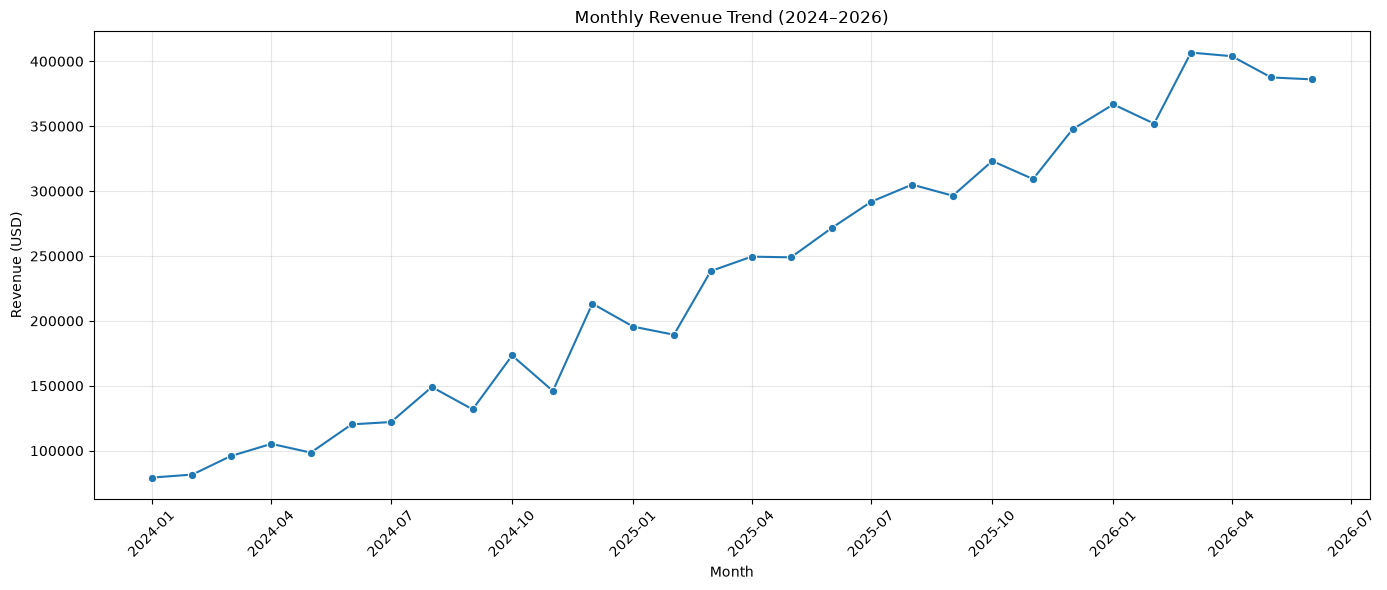

In [149]:

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="order_date",
    y="revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend (2024–2026)")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [150]:
# Calculate month-over-month revenue growth

monthly_revenue["revenue_change"] = (
    monthly_revenue["revenue"].diff()
)

monthly_revenue["mom_growth_pct"] = (
    monthly_revenue["revenue"].pct_change() * 100
)

monthly_revenue[
    ["order_date", "revenue", "revenue_change", "mom_growth_pct"]
].round(2)

C:\Users\user\AppData\Local\Temp\ipykernel_8636\4250691141.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,order_date,revenue,revenue_change,mom_growth_pct
0,2024-01-01,79272.02,NaN,NaN
1,2024-02-01,81608.23,2336.21,2.95
2,2024-03-01,95798.86,14190.63,17.39
3,2024-04-01,105267.84,9468.98,9.88
4,2024-05-01,98534.47,-6733.37,-6.40
5,2024-06-01,120285.16,21750.69,22.07
6,2024-07-01,122079.58,1794.42,1.49
7,2024-08-01,149062.32,26982.74,22.10
8,2024-09-01,131836.57,-17225.75,-11.56
9,2024-10-01,173348.36,41511.79,31.49


In [151]:

monthly_revenue["year"] = monthly_revenue["order_date"].dt.year

monthly_revenue["month"] = monthly_revenue["order_date"].dt.month

monthly_revenue["yoy_growth_pct"] = (
    monthly_revenue["revenue"].pct_change(periods=12) * 100
)

monthly_revenue[
    ["order_date", "revenue", "yoy_growth_pct"]
].round(2)


C:\Users\user\AppData\Local\Temp\ipykernel_8636\2962641552.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,order_date,revenue,yoy_growth_pct
0,2024-01-01,79272.02,NaN
1,2024-02-01,81608.23,NaN
2,2024-03-01,95798.86,NaN
3,2024-04-01,105267.84,NaN
4,2024-05-01,98534.47,NaN
5,2024-06-01,120285.16,NaN
6,2024-07-01,122079.58,NaN
7,2024-08-01,149062.32,NaN
8,2024-09-01,131836.57,NaN
9,2024-10-01,173348.36,NaN


In [152]:
# Annual revenue analysis

annual_revenue = (
    monthly_revenue
    .groupby("year")
    .agg(
        total_revenue=("revenue", "sum"),
        total_orders=("orders", "sum"),
        total_units=("units_sold", "sum")
    )
)

annual_revenue["yoy_growth_pct"] = (
    annual_revenue["total_revenue"].pct_change() * 100
)

annual_revenue.round(2)

,total_revenue,total_orders,total_units,yoy_growth_pct
year,,,,
2024,1516409.30,2990,8928,NaN
2025,3266803.07,6459,19325,115.43
2026,2303185.80,4551,13531,-29.50


In [153]:
# Compare January-June across years

first_half_revenue = (
    monthly_revenue[
        monthly_revenue["month"] <= 6
    ]
    .groupby("year")
    .agg(
        revenue=("revenue", "sum"),
        orders=("orders", "sum"),
        units_sold=("units_sold", "sum")
    )
)

first_half_revenue["revenue_growth_pct"] = (
    first_half_revenue["revenue"].pct_change() * 100
)

first_half_revenue.round(2)

,revenue,orders,units_sold,revenue_growth_pct
year,,,,
2024,580766.58,1135,3396,NaN
2025,1393415.55,2758,8250,139.93
2026,2303185.80,4551,13531,65.29


In [154]:

# Category-wise sales performance

sales_with_products = order_items.merge(
    products[["product_id", "product_name", "category", "brand"]],
    on="product_id",
    how="left"
)

category_sales = (
    sales_with_products
    .groupby("category")
    .agg(
        total_revenue=("line_total_usd", "sum"),
        total_units=("quantity", "sum"),
        total_items=("order_item_id", "count"),
        unique_products=("product_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

category_sales["revenue_contribution_pct"] = (
    category_sales["total_revenue"]
    / category_sales["total_revenue"].sum()
) * 100

category_sales.round(2)


,total_revenue,total_units,total_items,unique_products,revenue_contribution_pct
category,,,,,
Electronics,3527746.55,9019,6346,75,49.78
Sports,1172407.47,5530,3924,45,16.54
Apparel,1072433.35,10881,7804,90,15.13
Home & Kitchen,623454.39,5435,3859,45,8.80
Beauty,362591.00,5494,3868,45,5.12
Toys & Games,327765.41,5425,3870,45,4.63


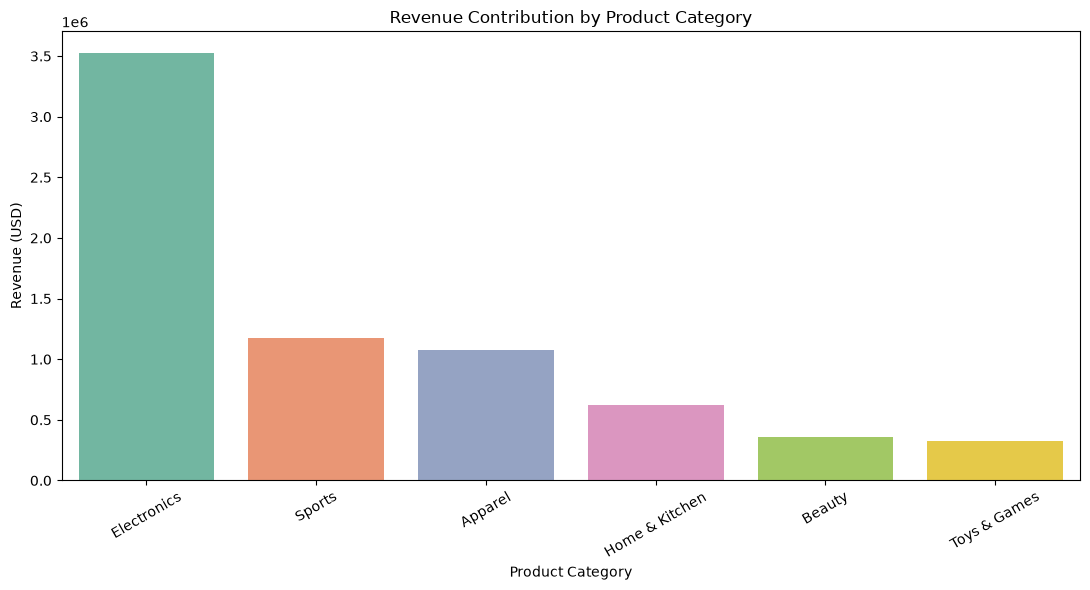

In [155]:

plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_sales.reset_index(),
    x="category",
    y="total_revenue",
    hue="category",
    palette="Set2",
    legend=False
)

plt.title("Revenue Contribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [156]:
category_sales["unit_contribution_pct"] = (
    category_sales["total_units"] /
    category_sales["total_units"].sum()
) * 100

category_sales[
    [
        "total_revenue",
        "revenue_contribution_pct",
        "total_units",
        "unit_contribution_pct"
    ]
].round(2)

,total_revenue,revenue_contribution_pct,total_units,unit_contribution_pct
category,,,,
Electronics,3527746.55,49.78,9019,21.58
Sports,1172407.47,16.54,5530,13.23
Apparel,1072433.35,15.13,10881,26.04
Home & Kitchen,623454.39,8.80,5435,13.01
Beauty,362591.00,5.12,5494,13.15
Toys & Games,327765.41,4.63,5425,12.98


In [157]:
brand_sales = (
    sales_with_products
    .groupby("brand")
    .agg(
        total_revenue=("line_total_usd", "sum"),
        total_units=("quantity", "sum"),
        total_items=("order_item_id", "count"),
        unique_products=("product_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

brand_sales

,total_revenue,total_units,total_items,unique_products
brand,,,,
Marlowe,1180494.81,5360,3852,44
Auralis,768578.03,4148,2977,35
Tanuki,746395.03,4344,3067,36
Brightfold,715678.60,4380,3138,37
Vantia,706804.16,4229,3038,35
Kestrel,659626.96,3255,2266,27
Ferrix,646407.34,3519,2490,28
Solstice,624360.15,4052,2807,33
Northline,525774.62,4383,3112,36


In [158]:
brand_sales["revenue_per_unit"] = (
    brand_sales["total_revenue"] / brand_sales["total_units"]
)

brand_sales["revenue_per_product"] = (
    brand_sales["total_revenue"] / brand_sales["unique_products"]
)

brand_sales[
    [
        "total_revenue",
        "total_units",
        "unique_products",
        "revenue_per_unit",
        "revenue_per_product"
    ]
].round(2).sort_values(
    "revenue_per_unit", ascending=False
)

,total_revenue,total_units,unique_products,revenue_per_unit,revenue_per_product
brand,,,,,
Marlowe,1180494.81,5360,44,220.24,26829.43
Kestrel,659626.96,3255,27,202.65,24430.63
Auralis,768578.03,4148,35,185.29,21959.37
Ferrix,646407.34,3519,28,183.69,23085.98
Tanuki,746395.03,4344,36,171.82,20733.20
Vantia,706804.16,4229,35,167.13,20194.40
Brightfold,715678.60,4380,37,163.40,19342.66
Solstice,624360.15,4052,33,154.09,18920.00
Corvid,512278.47,4114,34,124.52,15067.01


In [159]:
product_sales = (
    sales_with_products
    .groupby(["product_id", "product_name", "category", "brand"])
    .agg(
        total_revenue=("line_total_usd", "sum"),
        total_units=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

product_sales.head(10)


,,,,total_revenue,total_units,total_orders
product_id,product_name,category,brand,,,
PRD-0105,Corvid Wearable 0105,Electronics,Ferrix,106254.78,147,100
PRD-0118,Corvid Headphone 0118,Electronics,Ferrix,106002.98,130,93
PRD-0093,Marlowe Wearable 0093,Electronics,Kestrel,105228.42,132,87
PRD-0112,Vantia Headphone 0112,Electronics,Marlowe,100989.54,135,91
PRD-0132,Auralis Camera 0132,Electronics,Auralis,99319.79,127,89
PRD-0097,Brightfold Wearable 0097,Electronics,Marlowe,99180.42,119,90
PRD-0094,Kestrel Camera 0094,Electronics,Marlowe,94169.39,123,81
PRD-0159,Northline Wearable 0159,Electronics,Brightfold,92886.01,122,83
PRD-0092,Marlowe Camera 0092,Electronics,Kestrel,90319.36,117,78


In [160]:
top_products_by_units = (
    product_sales
    .sort_values("total_units", ascending=False)
    .head(10)
)

top_products_by_units


,,,,total_revenue,total_units,total_orders
product_id,product_name,category,brand,,,
PRD-0268,Tanuki Outdoor 0268,Sports,Corvid,27388.04,163,105
PRD-0182,Marlowe Textile 0182,Home & Kitchen,Vantia,18446.80,160,105
PRD-0048,Tanuki Dresse 0048,Apparel,Ferrix,12009.02,158,111
PRD-0067,Tanuki Footwear 0067,Apparel,Solstice,19690.62,158,111
PRD-0212,Brightfold Skincare 0212,Beauty,Northline,4004.10,157,105
PRD-0147,Tanuki Accessorie 0147,Electronics,Tanuki,84284.84,157,102
PRD-0111,Corvid Wearable 0111,Electronics,Solstice,12917.38,156,106
PRD-0167,Auralis Textile 0167,Home & Kitchen,Tanuki,11703.73,155,103
PRD-0087,Kestrel T-Shirt 0087,Apparel,Ferrix,21164.32,154,99


In [161]:
product_comparison = (
    product_sales
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

product_comparison["revenue_rank"] = (
    product_comparison.index + 1
)

product_comparison = product_comparison.sort_values(
    "total_units", ascending=False
).reset_index(drop=True)

product_comparison["units_rank"] = (
    product_comparison.index + 1
)

product_comparison[
    [
        "product_id",
        "product_name",
        "category",
        "brand",
        "total_revenue",
        "total_units",
        "revenue_rank",
        "units_rank"
    ]
].head(15)

,product_id,product_name,category,brand,total_revenue,total_units,revenue_rank,units_rank
0,PRD-0268,Tanuki Outdoor 0268,Sports,Corvid,27388.04,163,76,1
1,PRD-0182,Marlowe Textile 0182,Home & Kitchen,Vantia,18446.80,160,117,2
2,PRD-0048,Tanuki Dresse 0048,Apparel,Ferrix,12009.02,158,180,3
3,PRD-0067,Tanuki Footwear 0067,Apparel,Solstice,19690.62,158,107,4
4,PRD-0212,Brightfold Skincare 0212,Beauty,Northline,4004.10,157,309,5
5,PRD-0147,Tanuki Accessorie 0147,Electronics,Tanuki,84284.84,157,14,6
6,PRD-0111,Corvid Wearable 0111,Electronics,Solstice,12917.38,156,169,7
7,PRD-0167,Auralis Textile 0167,Home & Kitchen,Tanuki,11703.73,155,190,8
8,PRD-0087,Kestrel T-Shirt 0087,Apparel,Ferrix,21164.32,154,99,9
9,PRD-0338,Corvid Building Set 0338,Toys & Games,Marlowe,13848.55,151,155,10


In [162]:
product_comparison["rank_difference"] = (
    product_comparison["units_rank"] -
    product_comparison["revenue_rank"]
)

product_comparison[
    [
        "product_name",
        "total_revenue",
        "total_units",
        "revenue_rank",
        "units_rank",
        "rank_difference"
    ]
].sort_values(
    "rank_difference", ascending=False
).head(10)

,product_name,total_revenue,total_units,revenue_rank,units_rank,rank_difference
332,Ferrix Headphone 0133,80038.60,97,15,333,318
319,Solstice Wearable 0139,62018.15,101,22,320,298
342,Northline Camera 0144,35754.72,87,61,343,282
299,Ferrix Headphone 0122,72914.84,105,18,300,282
293,Marlowe Camera 0152,79650.01,106,16,294,278
335,Kestrel Headphone 0138,35632.95,96,62,336,274
322,Marlowe Wearable 0115,34835.54,100,63,323,260
264,Solstice Wearable 0123,86144.03,110,10,265,255
274,Tanuki Accessorie 0163,63166.69,108,21,275,254
309,Ferrix Camera 0145,35910.99,104,58,310,252


In [163]:
product_comparison.sort_values(
    "rank_difference", ascending=True
)[
    [
        "product_name",
        "category",
        "brand",
        "total_revenue",
        "total_units",
        "revenue_rank",
        "units_rank",
        "rank_difference"
    ]
].head(10)


,product_name,category,brand,total_revenue,total_units,revenue_rank,units_rank,rank_difference
4,Brightfold Skincare 0212,Beauty,Northline,4004.10,157,309,5,-304
34,Kestrel Haircare 0214,Beauty,Corvid,2420.59,143,332,35,-297
20,Ferrix Dresse 0088,Apparel,Vantia,3227.35,146,318,21,-297
26,Kestrel Fragrance 0237,Beauty,Kestrel,3357.55,145,316,27,-289
33,Auralis Skincare 0223,Beauty,Northline,3425.97,143,313,34,-279
18,Northline Textile 0187,Home & Kitchen,Brightfold,6155.16,147,280,19,-261
43,Corvid Fragrance 0225,Beauty,Solstice,4587.93,139,302,44,-258
47,Brightfold T-Shirt 0019,Apparel,Northline,4671.66,138,301,48,-253
14,Kestrel Building Set 0306,Toys & Games,Tanuki,7338.52,149,266,15,-251
50,Corvid Plush 0343,Toys & Games,Brightfold,5224.66,137,291,51,-240


In [164]:

# Combine order items with order status
status_analysis = order_items.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

# Calculate revenue and units for each order status
status_revenue = (
    status_analysis
    .groupby("order_status")
    .agg(
        total_revenue=("line_total_usd", "sum"),
        total_units=("quantity", "sum"),
        total_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

status_revenue


,total_revenue,total_units,total_items,total_orders
order_status,,,,
Delivered,6109150.81,35994,25509,12030
Cancelled,389897.29,2400,1707,807
Shipped,377731.73,2141,1552,724
Processing,209618.34,1249,903,439


In [165]:

# Keep only delivered orders
delivered_orders = orders[
    orders["order_status"] == "Delivered"
].copy()

# Connect delivered orders with order items
delivered_sales = order_items.merge(
    delivered_orders[
        ["order_id", "customer_id", "order_date",
         "shipping_country", "sales_channel",
         "device_type", "payment_method"]
    ],
    on="order_id",
    how="inner"
)

# Connect customer information
customer_sales = delivered_sales.merge(
    customers[
        ["customer_id", "country", "region",
         "acquisition_channel", "preferred_device",
         "newsletter_opt_in"]
    ],
    on="customer_id",
    how="left"
)

customer_sales.head()


,order_item_id,order_id,product_id,quantity,unit_price_local,line_discount_local,line_total_local,line_total_usd,unit_cost_usd,line_profit_usd,currency_code,calculated_profit,original_line_value,discount_check,expected_line_total_local,local_difference,discount_pct,profit_status,customer_id,order_date,shipping_country,sales_channel,device_type,payment_method,country,region,acquisition_channel,preferred_device,newsletter_opt_in
0,ITM-000001,ORD-000001,PRD-0061,1,42.78,0.00,42.78,42.78,18.99,23.79,USD,23.79,42.78,False,42.78,0.000000e+00,0.000000,Profitable,CST-00535,2025-06-21,United States,Mobile App,Mobile,Credit Card,United States,North America,Organic Search,Mobile,No
1,ITM-000002,ORD-000001,PRD-0311,1,96.79,0.00,96.79,96.79,53.60,43.19,USD,43.19,96.79,False,96.79,0.000000e+00,0.000000,Profitable,CST-00535,2025-06-21,United States,Mobile App,Mobile,Credit Card,United States,North America,Organic Search,Mobile,No
2,ITM-000003,ORD-000002,PRD-0335,1,282.11,0.00,282.11,75.23,39.08,36.15,SAR,36.15,282.11,False,282.11,0.000000e+00,0.000000,Profitable,CST-02247,2025-12-29,Saudi Arabia,Mobile App,Mobile,Cash on Delivery,Saudi Arabia,Middle East,Organic Search,Desktop,Yes
3,ITM-000004,ORD-000003,PRD-0092,2,1122.95,369.42,1876.48,1379.76,632.31,115.14,CAD,115.14,2245.90,False,1876.48,0.000000e+00,16.448640,Profitable,CST-01341,2026-04-07,Canada,Mobile App,Mobile,Digital Wallet,Canada,North America,Paid Social,Desktop,No
4,ITM-000005,ORD-000003,PRD-0301,1,96.07,31.15,64.92,47.74,35.15,12.59,CAD,12.59,96.07,False,64.92,1.421085e-14,32.424274,Profitable,CST-01341,2026-04-07,Canada,Mobile App,Mobile,Digital Wallet,Canada,North America,Paid Social,Desktop,No


In [166]:

print("Customer sales shape:", customer_sales.shape)

print(
    "Unique order items:",
    customer_sales["order_item_id"].nunique()
)

print(
    "Unique orders:",
    customer_sales["order_id"].nunique()
)

print(
    "Unique customers:",
    customer_sales["customer_id"].nunique()
)

print(
    "Missing customer IDs:",
    customer_sales["customer_id"].isna().sum()
)

print(
    "Total delivered revenue:",
    customer_sales["line_total_usd"].sum()
)


Customer sales shape: (25509, 29)
Unique order items: 25509
Unique orders: 12030
Unique customers: 2950
Missing customer IDs: 0
Total delivered revenue: 6109150.8100000005


In [167]:
 
country_analysis = (
    customer_sales
    .groupby("country")
    .agg(
        total_revenue=("line_total_usd", "sum"),
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique"),
        total_units=("quantity", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

country_analysis["revenue_contribution_pct"] = (
    country_analysis["total_revenue"]
    / country_analysis["total_revenue"].sum()
) * 100

country_analysis["revenue_per_customer"] = (
    country_analysis["total_revenue"]
    / country_analysis["total_customers"]
)

country_analysis


,total_revenue,total_orders,total_customers,total_units,revenue_contribution_pct,revenue_per_customer
country,,,,,,
United States,1370854.51,2719,653,8086,22.439363,2099.317779
United Kingdom,619920.63,1255,306,3767,10.147411,2025.884412
India,610469.11,1183,283,3563,9.992700,2157.134664
Germany,598041.36,1095,267,3324,9.789272,2239.855281
United Arab Emirates,433886.20,857,214,2607,7.102234,2027.505607
Saudi Arabia,412265.59,799,196,2352,6.748329,2103.395867
France,395418.27,758,197,2306,6.472557,2007.199340
Canada,382617.23,730,178,2204,6.263018,2149.535000
Japan,340243.27,675,172,2000,5.569404,1978.158547


In [168]:

country_analysis["orders_per_customer"] = (
    country_analysis["total_orders"]
    / country_analysis["total_customers"]
)

country_analysis["revenue_per_order"] = (
    country_analysis["total_revenue"]
    / country_analysis["total_orders"]
)

country_analysis[
    [
        "total_customers",
        "total_orders",
        "revenue_per_customer",
        "orders_per_customer",
        "revenue_per_order"
    ]
].sort_values("revenue_per_customer", ascending=False).round(2)


,total_customers,total_orders,revenue_per_customer,orders_per_customer,revenue_per_order
country,,,,,
Germany,267,1095,2239.86,4.10,546.16
India,283,1183,2157.13,4.18,516.03
Canada,178,730,2149.54,4.10,524.13
Saudi Arabia,196,799,2103.40,4.08,515.98
United States,653,2719,2099.32,4.16,504.18
United Arab Emirates,214,857,2027.51,4.00,506.28
Spain,132,564,2026.38,4.27,474.26
United Kingdom,306,1255,2025.88,4.10,493.96
Brazil,169,703,2010.10,4.16,483.23


In [169]:

acquisition_analysis = (
    customer_sales
    .groupby("acquisition_channel")
    .agg(
        total_revenue=("line_total_usd", "sum"),
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

acquisition_analysis["revenue_contribution_pct"] = (
    acquisition_analysis["total_revenue"]
    / acquisition_analysis["total_revenue"].sum()
) * 100

acquisition_analysis["revenue_per_customer"] = (
    acquisition_analysis["total_revenue"]
    / acquisition_analysis["total_customers"]
)

acquisition_analysis["orders_per_customer"] = (
    acquisition_analysis["total_orders"]
    / acquisition_analysis["total_customers"]
)

acquisition_analysis.round(2)


,total_revenue,total_customers,total_orders,total_units,revenue_contribution_pct,revenue_per_customer,orders_per_customer
acquisition_channel,,,,,,,
Organic Search,1351188.15,660,2693,7929,22.12,2047.25,4.08
Paid Social,1156072.20,562,2289,6778,18.92,2057.07,4.07
Paid Search,1049903.84,514,2128,6179,17.19,2042.61,4.14
Email,903356.64,418,1722,5344,14.79,2161.14,4.12
Direct,676950.32,340,1325,4064,11.08,1991.03,3.90
Affiliate,526830.37,240,1002,3100,8.62,2195.13,4.18
Marketplace,444849.29,216,871,2600,7.28,2059.49,4.03


In [170]:

# Calculate order frequency for each customer
customer_frequency = (
    customer_sales
    .groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("line_total_usd", "sum"),
        total_units=("quantity", "sum")
    )
)

# Classify customers based on purchase frequency
customer_frequency["customer_segment"] = pd.cut(
    customer_frequency["total_orders"],
    bins=[0, 1, 3, 5, float("inf")],
    labels=[
        "One-time",
        "Occasional",
        "Regular",
        "Frequent"
    ]
)

customer_frequency.head()


,total_orders,total_revenue,total_units,customer_segment
customer_id,,,,
CST-00001,7,3113.13,22,Frequent
CST-00002,3,1256.91,8,Occasional
CST-00003,3,1480.80,6,Occasional
CST-00004,2,660.80,4,Occasional
CST-00005,4,840.83,6,Regular


In [172]:
segment_analysis = (
    customer_frequency
    .groupby("customer_segment", observed=False)
    .agg(
        total_customers=("total_orders", "count"),
        total_revenue=("total_revenue", "sum"),
        total_orders=("total_orders", "sum"),
        total_units=("total_units", "sum")
    )
)

segment_analysis["customer_share_pct"] = (
    segment_analysis["total_customers"]
    / segment_analysis["total_customers"].sum()
) * 100

segment_analysis["revenue_contribution_pct"] = (
    segment_analysis["total_revenue"]
    / segment_analysis["total_revenue"].sum()
) * 100

segment_analysis["revenue_per_customer"] = (
    segment_analysis["total_revenue"]
    / segment_analysis["total_customers"]
)

segment_analysis["orders_per_customer"] = (
    segment_analysis["total_orders"]
    / segment_analysis["total_customers"]
)

segment_analysis.round(2)

,total_customers,total_revenue,total_orders,total_units,customer_share_pct,revenue_contribution_pct,revenue_per_customer,orders_per_customer
customer_segment,,,,,,,,
One-time,205,105063.34,205,630,6.95,1.72,512.50,1.00
Occasional,1033,1347176.44,2646,7963,35.02,22.05,1304.14,2.56
Regular,1075,2454288.23,4783,14319,36.44,40.17,2283.06,4.45
Frequent,637,2202622.80,4396,13082,21.59,36.05,3457.81,6.90


In [173]:

segment_analysis["revenue_per_order"] = (
    segment_analysis["total_revenue"]
    / segment_analysis["total_orders"]
)

segment_analysis[
    [
        "revenue_per_customer",
        "orders_per_customer",
        "revenue_per_order"
    ]
].round(2)


,revenue_per_customer,orders_per_customer,revenue_per_order
customer_segment,,,
One-time,512.50,1.00,512.50
Occasional,1304.14,2.56,509.14
Regular,2283.06,4.45,513.13
Frequent,3457.81,6.90,501.05


In [174]:
# Latest delivered order date in the dataset
analysis_date = delivered_sales["order_date"].max()

# Calculate each customer's latest purchase date
customer_recency = (
    delivered_sales
    .groupby("customer_id")
    .agg(
        last_purchase_date=("order_date", "max"),
        total_orders=("order_id", "nunique"),
        total_revenue=("line_total_usd", "sum")
    )
)

# Days since the customer's last purchase
customer_recency["recency_days"] = (
    analysis_date - customer_recency["last_purchase_date"]
).dt.days

customer_recency.head()

,last_purchase_date,total_orders,total_revenue,recency_days
customer_id,,,,
CST-00001,2026-05-13,7,3113.13,47
CST-00002,2026-06-25,3,1256.91,4
CST-00003,2025-09-07,3,1480.80,295
CST-00004,2026-05-06,2,660.80,54
CST-00005,2025-10-11,4,840.83,261


In [175]:
customer_recency["recency_days"].describe().round(2)

count    2950.00
mean      155.75
std       156.57
min         0.00
25%        40.00
50%       102.00
75%       223.00
max       900.00
Name: recency_days, dtype: float64

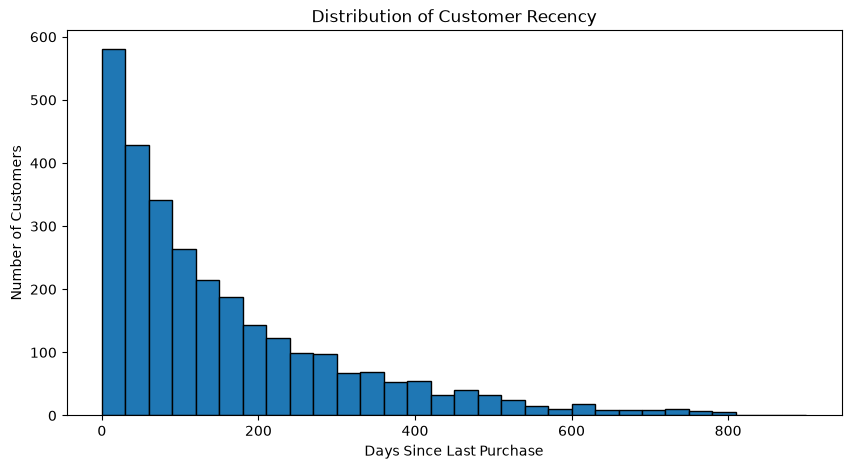

In [176]:
customer_recency["recency_days"].plot(
    kind="hist",
    bins=30,
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Distribution of Customer Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.show()

In [177]:
customer_recency["recency_segment"] = pd.cut(
    customer_recency["recency_days"],
    bins=[-1, 30, 90, 180, float("inf")],
    labels=["Recent", "Active", "At Risk", "Inactive"]
)

recency_analysis = (
    customer_recency
    .groupby("recency_segment", observed=False)
    .agg(
        customers=("recency_days", "count"),
        avg_orders=("total_orders", "mean"),
        avg_revenue=("total_revenue", "mean")
    )
)

recency_analysis["customer_share_pct"] = (
    recency_analysis["customers"]
    / recency_analysis["customers"].sum()
) * 100

recency_analysis.round(2)

,customers,avg_orders,avg_revenue,customer_share_pct
recency_segment,,,,
Recent,597,4.75,2413.51,20.24
Active,768,4.57,2332.65,26.03
At Risk,658,4.16,2124.48,22.31
Inactive,927,3.18,1595.37,31.42


In [178]:
# Total units sold in delivered orders
total_delivered_units = delivered_sales["quantity"].sum()

# Total units returned
total_returned_units = returns["quantity_returned"].sum()

# Overall unit return rate
overall_return_rate = (
    total_returned_units / total_delivered_units
) * 100

print("Total delivered units:", total_delivered_units)
print("Total returned units:", total_returned_units)
print("Overall unit return rate:", round(overall_return_rate, 2), "%")

Total delivered units: 35994
Total returned units: 2882
Overall unit return rate: 8.01 %


In [179]:
# Connect return records with their original order status
returns_status = returns.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

# Examine returned quantities by order status
returns_status_analysis = (
    returns_status
    .groupby("order_status")
    .agg(
        return_records=("return_id", "count"),
        returned_units=("quantity_returned", "sum"),
        refund_amount_usd=("refund_amount_usd", "sum")
    )
)

returns_status_analysis

,return_records,returned_units,refund_amount_usd
order_status,,,
Delivered,2433,2882,410427.05


In [180]:
return_reason_analysis = (
    returns
    .groupby("return_reason")
    .agg(
        return_records=("return_id", "count"),
        returned_units=("quantity_returned", "sum"),
        refund_amount=("refund_amount_usd", "sum")
    )
    .sort_values("returned_units", ascending=False)
)

return_reason_analysis["return_share_pct"] = (
    return_reason_analysis["returned_units"]
    / return_reason_analysis["returned_units"].sum()
) * 100

return_reason_analysis.round(2)

,return_records,returned_units,refund_amount,return_share_pct
return_reason,,,,
Wrong size or fit,719,838,116858.82,29.08
Not as described,487,573,76883.91,19.88
Changed mind,409,499,75326.77,17.31
Damaged on arrival,312,372,53315.92,12.91
Quality below expectation,302,361,53355.87,12.53
Late delivery,204,239,34685.76,8.29


In [181]:
# Total delivered units by category
category_delivered = (
    delivered_sales
    .merge(
        products[["product_id", "category"]],
        on="product_id",
        how="left"
    )
    .groupby("category")
    .agg(
        delivered_units=("quantity", "sum")
    )
)

# Returned units by category
category_returned = (
    returns
    .merge(
        products[["product_id", "category"]],
        on="product_id",
        how="left"
    )
    .groupby("category")
    .agg(
        returned_units=("quantity_returned", "sum"),
        refund_amount=("refund_amount_usd", "sum"),
        return_records=("return_id", "count")
    )
)

# Combine both datasets
category_returns = category_delivered.merge(
    category_returned,
    on="category",
    how="left"
)

# Calculate category return rate
category_returns["return_rate_pct"] = (
    category_returns["returned_units"]
    / category_returns["delivered_units"]
) * 100

category_returns.sort_values(
    "return_rate_pct",
    ascending=False
).round(2)

,delivered_units,returned_units,refund_amount,return_records,return_rate_pct
category,,,,,
Apparel,9353,1435,142470.53,1214,15.34
Sports,4780,410,87195.93,342,8.58
Home & Kitchen,4727,257,30936.77,221,5.44
Toys & Games,4653,250,15001.70,206,5.37
Beauty,4720,218,14046.77,191,4.62
Electronics,7761,312,120775.35,259,4.02


In [182]:
# Delivered units by brand
brand_delivered = (
    delivered_sales
    .merge(
        products[["product_id", "brand"]],
        on="product_id",
        how="left"
    )
    .groupby("brand")
    .agg(
        delivered_units=("quantity", "sum")
    )
)

# Returned units by brand
brand_returned = (
    returns
    .merge(
        products[["product_id", "brand"]],
        on="product_id",
        how="left"
    )
    .groupby("brand")
    .agg(
        returned_units=("quantity_returned", "sum"),
        refund_amount=("refund_amount_usd", "sum"),
        return_records=("return_id", "count")
    )
)

# Combine
brand_returns = brand_delivered.merge(
    brand_returned,
    on="brand",
    how="left"
)

brand_returns["return_rate_pct"] = (
    brand_returns["returned_units"]
    / brand_returns["delivered_units"]
) * 100

brand_returns.sort_values(
    "return_rate_pct",
    ascending=False
).round(2)

,delivered_units,returned_units,refund_amount,return_records,return_rate_pct
brand,,,,,
Vantia,3591,345,42459.98,286,9.61
Ferrix,3069,266,41805.19,224,8.67
Solstice,3473,293,37348.38,242,8.44
Auralis,3580,296,49359.50,259,8.27
Marlowe,4605,371,59935.36,302,8.06
Kestrel,2807,224,39338.69,194,7.98
Brightfold,3764,295,40741.98,253,7.84
Northline,3784,283,33024.77,245,7.48
Corvid,3543,261,30112.61,220,7.37


In [183]:
# Delivered units by product
product_delivered = (
    delivered_sales
    .groupby("product_id")
    .agg(
        delivered_units=("quantity", "sum")
    )
)

# Returned units by product
product_returned = (
    returns
    .groupby("product_id")
    .agg(
        returned_units=("quantity_returned", "sum"),
        refund_amount=("refund_amount_usd", "sum"),
        return_records=("return_id", "count")
    )
)

# Combine with product information
product_returns = (
    product_delivered
    .merge(product_returned, on="product_id", how="left")
    .merge(
        products[["product_id", "product_name", "category", "brand"]],
        on="product_id",
        how="left"
    )
)

# Products without returns should have zero returned units
product_returns["returned_units"] = (
    product_returns["returned_units"].fillna(0)
)

product_returns["return_rate_pct"] = (
    product_returns["returned_units"]
    / product_returns["delivered_units"]
) * 100

# Show products with the highest return rates
product_returns.sort_values(
    "return_rate_pct",
    ascending=False
).head(15).round(2)

,product_id,delivered_units,returned_units,refund_amount,return_records,product_name,category,brand,return_rate_pct
61,PRD-0062,107,30.0,4988.70,25.0,Marlowe Dresse 0062,Apparel,Marlowe,28.04
27,PRD-0028,105,26.0,2585.63,19.0,Solstice Footwear 0028,Apparel,Brightfold,24.76
14,PRD-0015,112,26.0,4356.96,22.0,Corvid T-Shirt 0015,Apparel,Vantia,23.21
67,PRD-0068,104,24.0,1495.21,21.0,Tanuki T-Shirt 0068,Apparel,Solstice,23.08
7,PRD-0008,87,20.0,2099.82,17.0,Vantia Footwear 0008,Apparel,Kestrel,22.99
77,PRD-0078,87,20.0,1405.61,13.0,Kestrel Dresse 0078,Apparel,Solstice,22.99
30,PRD-0031,105,24.0,4011.45,20.0,Vantia Footwear 0031,Apparel,Vantia,22.86
35,PRD-0036,107,24.0,1685.40,17.0,Marlowe Jacket 0036,Apparel,Marlowe,22.43
56,PRD-0057,97,21.0,2814.32,16.0,Tanuki Dresse 0057,Apparel,Marlowe,21.65
29,PRD-0030,98,21.0,1291.29,18.0,Marlowe Jacket 0030,Apparel,Ferrix,21.43


In [184]:
# Join return records with product categories
returns_with_category = returns.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Compare return reasons across categories
category_reason_analysis = (
    returns_with_category
    .groupby(["category", "return_reason"])
    .agg(
        returned_units=("quantity_returned", "sum"),
        refund_amount=("refund_amount_usd", "sum")
    )
    .reset_index()
)

# Calculate percentage within each category
category_reason_analysis["reason_share_pct"] = (
    category_reason_analysis["returned_units"]
    / category_reason_analysis
        .groupby("category")["returned_units"]
        .transform("sum")
) * 100

category_reason_analysis.sort_values(
    ["category", "returned_units"],
    ascending=[True, False]
).round(2)

,category,return_reason,returned_units,refund_amount,reason_share_pct
5,Apparel,Wrong size or fit,394,39421.80,27.46
3,Apparel,Not as described,319,30925.00,22.23
0,Apparel,Changed mind,223,22815.17,15.54
4,Apparel,Quality below expectation,189,18101.91,13.17
1,Apparel,Damaged on arrival,188,19096.19,13.10
2,Apparel,Late delivery,122,12110.46,8.50
11,Beauty,Wrong size or fit,76,4887.42,34.86
6,Beauty,Changed mind,43,2962.11,19.72
9,Beauty,Not as described,35,2198.91,16.06
7,Beauty,Damaged on arrival,29,1861.90,13.30


In [185]:
# Join returns with product details
returns_with_details = returns.merge(
    products[["product_id", "product_name", "category", "subcategory", "brand"]],
    on="product_id",
    how="left"
)

# Analyse return reasons by subcategory
subcategory_returns = (
    returns_with_details
    .groupby(["category", "subcategory", "return_reason"])
    .agg(
        returned_units=("quantity_returned", "sum"),
        refund_amount=("refund_amount_usd", "sum")
    )
    .reset_index()
)

subcategory_returns.sort_values(
    ["category", "returned_units"],
    ascending=[True, False]
).round(2)

,category,subcategory,return_reason,returned_units,refund_amount
11,Apparel,Footwear,Wrong size or fit,121,12466.84
17,Apparel,Jackets,Wrong size or fit,103,10290.83
5,Apparel,Dresses,Wrong size or fit,102,9828.77
3,Apparel,Dresses,Not as described,95,9770.44
9,Apparel,Footwear,Not as described,86,8587.14
...,...,...,...,...,...
120,Toys & Games,Plush,Changed mind,9,751.68
121,Toys & Games,Plush,Damaged on arrival,6,380.97
114,Toys & Games,Building Sets,Changed mind,5,430.80
116,Toys & Games,Building Sets,Late delivery,5,283.67


In [186]:
apparel_subcategory_analysis = (
    returns_with_details[
        returns_with_details["category"] == "Apparel"
    ]
    .groupby(["subcategory", "return_reason"])
    .agg(
        returned_units=("quantity_returned", "sum"),
        refund_amount=("refund_amount_usd", "sum")
    )
    .reset_index()
    .sort_values("returned_units", ascending=False)
)

apparel_subcategory_analysis.round(2)

,subcategory,return_reason,returned_units,refund_amount
11,Footwear,Wrong size or fit,121,12466.84
17,Jackets,Wrong size or fit,103,10290.83
5,Dresses,Wrong size or fit,102,9828.77
3,Dresses,Not as described,95,9770.44
9,Footwear,Not as described,86,8587.14
10,Footwear,Quality below expectation,72,7312.28
21,T-Shirts,Not as described,69,6022.70
15,Jackets,Not as described,69,6544.72
23,T-Shirts,Wrong size or fit,68,6835.36
18,T-Shirts,Changed mind,62,6168.94


In [187]:
# Analyse order status distribution
order_status_analysis = (
    orders
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_orders", ascending=False)
)

order_status_analysis["order_share_pct"] = (
    order_status_analysis["total_orders"]
    / orders["order_id"].nunique()
) * 100

order_status_analysis.round(2)

,total_orders,order_share_pct
order_status,,
Delivered,12030,85.93
Cancelled,807,5.76
Shipped,724,5.17
Processing,439,3.14


In [188]:
# Analyse delivery time for orders with recorded delivery days
delivery_analysis = (
    orders[orders["delivery_days"].notna()]
    ["delivery_days"]
    .describe()
)

delivery_analysis

count    12754.000000
mean         6.487220
std          3.458874
min          1.000000
25%          3.000000
50%          6.000000
75%          9.000000
max         12.000000
Name: delivery_days, dtype: float64

In [189]:
# Filter only successfully delivered orders
delivered_delivery = orders[
    orders["order_status"] == "Delivered"
].copy()

# Calculate delivery statistics
delivered_delivery["delivery_days"].describe()

count    12030.000000
mean         6.478304
std          3.460114
min          1.000000
25%          3.000000
50%          6.000000
75%          9.000000
max         12.000000
Name: delivery_days, dtype: float64

In [190]:
# Analyse delivery performance by shipping country
delivery_by_country = (
    delivered_delivery
    .groupby("shipping_country")
    .agg(
        total_orders=("order_id", "nunique"),
        avg_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median"),
        min_delivery_days=("delivery_days", "min"),
        max_delivery_days=("delivery_days", "max")
    )
    .sort_values("avg_delivery_days", ascending=False)
)

delivery_by_country.round(2)

,total_orders,avg_delivery_days,median_delivery_days,min_delivery_days,max_delivery_days
shipping_country,,,,,
Brazil,703,6.70,7.0,1.0,12.0
Germany,1095,6.61,7.0,1.0,12.0
Saudi Arabia,799,6.55,7.0,1.0,12.0
United Kingdom,1255,6.51,6.0,1.0,12.0
United States,2719,6.51,7.0,1.0,12.0
Spain,564,6.48,6.0,1.0,12.0
India,1183,6.42,6.0,1.0,12.0
United Arab Emirates,857,6.41,6.0,1.0,12.0
Australia,692,6.40,7.0,1.0,12.0


In [191]:
delivery_by_channel = (
    delivered_delivery
    .groupby("sales_channel")
    .agg(
        total_orders=("order_id", "nunique"),
        avg_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median")
    )
    .sort_values("avg_delivery_days", ascending=False)
)

delivery_by_channel.round(2)

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


,total_orders,avg_delivery_days,median_delivery_days
sales_channel,,,
Mobile App,5050,6.52,7.0
Marketplace,1564,6.49,7.0
Web Store,4020,6.47,6.0
Social Shop,1396,6.35,6.0


In [192]:
delivery_by_region = (
    delivered_delivery
    .groupby("shipping_region")
    .agg(
        total_orders=("order_id", "nunique"),
        avg_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median")
    )
    .sort_values("avg_delivery_days", ascending=False)
)

delivery_by_region.round(2)

,total_orders,avg_delivery_days,median_delivery_days
shipping_region,,,
Latin America,703,6.70,7.0
Europe,3672,6.51,6.0
North America,3449,6.48,6.0
Middle East,1656,6.48,7.0
Asia-Pacific,2550,6.36,6.0


In [193]:
# Identify orders that had at least one return
returned_order_ids = returns["order_id"].unique()

# Create a return indicator
delivered_delivery["was_returned"] = (
    delivered_delivery["order_id"].isin(returned_order_ids)
)

# Compare delivery time between returned and non-returned orders
delivery_return_analysis = (
    delivered_delivery
    .groupby("was_returned")
    .agg(
        total_orders=("order_id", "nunique"),
        avg_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median")
    )
)

delivery_return_analysis.round(2)

,total_orders,avg_delivery_days,median_delivery_days
was_returned,,,
False,9807,6.50,7.0
True,2223,6.37,6.0


In [194]:
# Aggregate actual profitability by category

category_profitability = (
    delivered_sales_with_products
    .groupby("category")
    .agg(
        revenue=("line_total_usd", "sum"),
        gross_profit=("line_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
)

# Calculate gross margin percentage

category_profitability["gross_margin_pct"] = (
    category_profitability["gross_profit"]
    / category_profitability["revenue"]
) * 100

# Calculate each category's contribution to total gross profit

category_profitability["profit_contribution_pct"] = (
    category_profitability["gross_profit"]
    / category_profitability["gross_profit"].sum()
) * 100

# Sort by gross profit

category_profitability = category_profitability.sort_values(
    "gross_profit",
    ascending=False
)

category_profitability.round(2)


NameError: name 'delivered_sales_with_products' is not defined

In [195]:
delivered_sales_with_products = delivered_sales.merge(
    products[["product_id", "category", "brand", "product_name"]],
    on="product_id",
    how="left"
)

print(delivered_sales_with_products.shape)
print(delivered_sales_with_products.columns.tolist())

(25509, 27)
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_local', 'line_discount_local', 'line_total_local', 'line_total_usd', 'unit_cost_usd', 'line_profit_usd', 'currency_code', 'calculated_profit', 'original_line_value', 'discount_check', 'expected_line_total_local', 'local_difference', 'discount_pct', 'profit_status', 'customer_id', 'order_date', 'shipping_country', 'sales_channel', 'device_type', 'payment_method', 'category', 'brand', 'product_name']


In [196]:
# Aggregate actual profitability by category

category_profitability = (
    delivered_sales_with_products
    .groupby("category")
    .agg(
        revenue=("line_total_usd", "sum"),
        gross_profit=("line_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
)

# Calculate gross margin percentage

category_profitability["gross_margin_pct"] = (
    category_profitability["gross_profit"]
    / category_profitability["revenue"]
) * 100

# Calculate each category's contribution to total gross profit

category_profitability["profit_contribution_pct"] = (
    category_profitability["gross_profit"]
    / category_profitability["gross_profit"].sum()
) * 100

# Sort by gross profit

category_profitability = category_profitability.sort_values(
    "gross_profit",
    ascending=False
)

category_profitability.round(2)

,revenue,gross_profit,units_sold,total_orders,gross_margin_pct,profit_contribution_pct
category,,,,,,
Electronics,3037892.60,686160.62,7761,4553,22.59,32.99
Apparel,921879.37,480329.10,9353,5320,52.10,23.09
Sports,1015061.33,385651.58,4780,2997,37.99,18.54
Home & Kitchen,542689.60,217697.86,4727,2985,40.11,10.47
Beauty,311049.75,184867.95,4720,2970,59.43,8.89
Toys & Games,280578.16,125349.52,4653,2944,44.68,6.03


In [197]:
# Check restocking status

print("Restocking status:")
print(returns["restocked"].value_counts(dropna=False))

print("\nReturned quantity:")
print(returns["quantity_returned"].describe())

print("\nRefund amount:")
print(returns["refund_amount_usd"].describe())

Restocking status:
restocked
Yes    1532
No      901
Name: count, dtype: int64

Returned quantity:
count    2433.000000
mean        1.184546
std         0.480773
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         4.000000
Name: quantity_returned, dtype: float64

Refund amount:
count    2433.000000
mean      168.691759
std       188.010673
min         8.160000
25%        66.380000
50%       110.520000
75%       184.680000
max      2476.020000
Name: refund_amount_usd, dtype: float64


In [198]:
restocking_analysis = (
    returns
    .groupby("restocked")
    .agg(
        return_records=("return_id", "count"),
        returned_units=("quantity_returned", "sum"),
        total_refund=("refund_amount_usd", "sum"),
        avg_refund=("refund_amount_usd", "mean")
    )
)

restocking_analysis["record_share_pct"] = (
    restocking_analysis["return_records"]
    / restocking_analysis["return_records"].sum()
) * 100

restocking_analysis.round(2)

,return_records,returned_units,total_refund,avg_refund,record_share_pct
restocked,,,,,
No,901,1075,158334.05,175.73,37.03
Yes,1532,1807,252093.00,164.55,62.97


In [199]:
non_restocked_reasons = (
    returns[returns["restocked"] == "No"]
    .groupby("return_reason")
    .agg(
        return_records=("return_id", "count"),
        returned_units=("quantity_returned", "sum"),
        total_refund=("refund_amount_usd", "sum")
    )
    .sort_values("return_records", ascending=False)
)

non_restocked_reasons.round(2)

,return_records,returned_units,total_refund
return_reason,,,
Wrong size or fit,268,309,46182.66
Not as described,179,216,29779.75
Changed mind,159,196,28636.30
Quality below expectation,123,150,21225.99
Damaged on arrival,111,129,20638.26
Late delivery,61,75,11871.09


In [200]:
reason_restocking_analysis = (
    returns
    .groupby("return_reason")
    .agg(
        total_returns=("return_id", "count"),
        not_restocked=(
            "restocked",
            lambda x: (x == "No").sum()
        ),
        total_refunds=("refund_amount_usd", "sum")
    )
)

reason_restocking_analysis["non_restocking_rate_pct"] = (
    reason_restocking_analysis["not_restocked"]
    / reason_restocking_analysis["total_returns"]
) * 100

reason_restocking_analysis = (
    reason_restocking_analysis
    .sort_values("non_restocking_rate_pct", ascending=False)
)

reason_restocking_analysis.round(2)

,total_returns,not_restocked,total_refunds,non_restocking_rate_pct
return_reason,,,,
Quality below expectation,302,123,53355.87,40.73
Changed mind,409,159,75326.77,38.88
Wrong size or fit,719,268,116858.82,37.27
Not as described,487,179,76883.91,36.76
Damaged on arrival,312,111,53315.92,35.58
Late delivery,204,61,34685.76,29.90


In [201]:
brand_profitability = (
    delivered_sales_with_products
    .groupby("brand")
    .agg(
        revenue=("line_total_usd", "sum"),
        gross_profit=("line_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique")
    )
)

brand_profitability["gross_margin_pct"] = (
    brand_profitability["gross_profit"]
    / brand_profitability["revenue"]
) * 100

brand_profitability["profit_contribution_pct"] = (
    brand_profitability["gross_profit"]
    / brand_profitability["gross_profit"].sum()
) * 100

brand_profitability = brand_profitability.sort_values(
    "gross_profit",
    ascending=False
)

brand_profitability.round(2)

,revenue,gross_profit,units_sold,total_orders,unique_products,gross_margin_pct,profit_contribution_pct
brand,,,,,,,
Marlowe,1010758.56,306821.53,4605,2954,44,30.36,14.75
Auralis,668458.33,241598.91,3580,2335,35,36.14,11.62
Tanuki,647899.98,208894.12,3778,2433,36,32.24,10.04
Vantia,599484.61,207832.01,3591,2402,35,34.67,9.99
Brightfold,623507.50,207551.80,3764,2461,37,33.29,9.98
Ferrix,570653.88,197538.66,3069,2021,28,34.62,9.50
Solstice,532801.34,185656.46,3473,2217,33,34.85,8.93
Kestrel,568261.37,181227.12,2807,1824,27,31.89,8.71
Northline,448487.54,178437.40,3784,2440,36,39.79,8.58


In [202]:
product_profitability = (
    delivered_sales_with_products
    .groupby(["product_id", "product_name", "category", "brand"])
    .agg(
        revenue=("line_total_usd", "sum"),
        gross_profit=("line_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
)

product_profitability["gross_margin_pct"] = (
    product_profitability["gross_profit"]
    / product_profitability["revenue"]
) * 100

product_profitability = product_profitability.sort_values(
    "gross_profit",
    ascending=False
)

product_profitability.round(2)

,,,,revenue,gross_profit,units_sold,total_orders,gross_margin_pct
product_id,product_name,category,brand,,,,,
PRD-0093,Marlowe Wearable 0093,Electronics,Kestrel,91907.71,26036.86,115,73,28.33
PRD-0118,Corvid Headphone 0118,Electronics,Ferrix,93882.71,24581.41,115,83,26.18
PRD-0097,Brightfold Wearable 0097,Electronics,Marlowe,86376.00,23703.58,103,77,27.44
PRD-0132,Auralis Camera 0132,Electronics,Auralis,86608.22,20736.92,110,78,23.94
PRD-0094,Kestrel Camera 0094,Electronics,Marlowe,81041.73,19905.17,106,70,24.56
...,...,...,...,...,...,...,...,...
PRD-0192,Corvid Textile 0192,Home & Kitchen,Solstice,1494.57,604.11,97,68,40.42
PRD-0175,Vantia Storage 0175,Home & Kitchen,Solstice,1407.56,536.89,83,65,38.14
PRD-0178,Northline Lighting 0178,Home & Kitchen,Solstice,1370.20,524.45,85,68,38.28


In [203]:
top_10_profitable_products = (
    product_profitability
    .head(10)
)

top_10_profitable_products.round(2)

,,,,revenue,gross_profit,units_sold,total_orders,gross_margin_pct
product_id,product_name,category,brand,,,,,
PRD-0093,Marlowe Wearable 0093,Electronics,Kestrel,91907.71,26036.86,115,73,28.33
PRD-0118,Corvid Headphone 0118,Electronics,Ferrix,93882.71,24581.41,115,83,26.18
PRD-0097,Brightfold Wearable 0097,Electronics,Marlowe,86376.00,23703.58,103,77,27.44
PRD-0132,Auralis Camera 0132,Electronics,Auralis,86608.22,20736.92,110,78,23.94
PRD-0094,Kestrel Camera 0094,Electronics,Marlowe,81041.73,19905.17,106,70,24.56
PRD-0290,Corvid Cycling 0290,Sports,Auralis,46992.72,19376.39,119,85,41.23
PRD-0105,Corvid Wearable 0105,Electronics,Ferrix,92810.98,18878.18,128,86,20.34
PRD-0282,Auralis Fitnes 0282,Sports,Brightfold,46750.46,18599.64,127,91,39.78
PRD-0147,Tanuki Accessorie 0147,Electronics,Tanuki,75359.10,17446.70,140,91,23.15


In [204]:
bottom_10_profitable_products = (
    product_profitability
    .tail(10)
    .sort_values("gross_profit", ascending=True)
)

bottom_10_profitable_products.round(2)

,,,,revenue,gross_profit,units_sold,total_orders,gross_margin_pct
product_id,product_name,category,brand,,,,,
PRD-0203,Tanuki Lighting 0203,Home & Kitchen,Marlowe,1217.00,493.16,104,78,40.52
PRD-0243,Vantia Fragrance 0243,Beauty,Solstice,886.34,511.42,91,63,57.70
PRD-0178,Northline Lighting 0178,Home & Kitchen,Solstice,1370.20,524.45,85,68,38.28
PRD-0175,Vantia Storage 0175,Home & Kitchen,Solstice,1407.56,536.89,83,65,38.14
PRD-0192,Corvid Textile 0192,Home & Kitchen,Solstice,1494.57,604.11,97,68,40.42
PRD-0339,Tanuki Board Game 0339,Toys & Games,Brightfold,1663.80,699.54,99,77,42.04
PRD-0265,Vantia Fitnes 0265,Sports,Marlowe,1770.06,718.62,104,74,40.60
PRD-0066,Corvid Jacket 0066,Apparel,Vantia,1642.12,796.27,97,79,48.49
PRD-0309,Solstice Building Set 0309,Toys & Games,Northline,1929.27,802.13,97,68,41.58


In [205]:
# Top 10 products by gross margin
top_10_margin = (
    product_profitability
    .sort_values("gross_margin_pct", ascending=False)
    .head(10)
)

top_10_margin.round(2)

,,,,revenue,gross_profit,units_sold,total_orders,gross_margin_pct
product_id,product_name,category,brand,,,,,
PRD-0212,Brightfold Skincare 0212,Beauty,Northline,3397.39,2136.45,134,91,62.89
PRD-0232,Kestrel Fragrance 0232,Beauty,Tanuki,10354.28,6474.99,113,78,62.53
PRD-0240,Northline Fragrance 0240,Beauty,Northline,7628.70,4766.94,132,89,62.49
PRD-0235,Northline Fragrance 0235,Beauty,Ferrix,6146.49,3836.20,103,79,62.41
PRD-0241,Auralis Fragrance 0241,Beauty,Brightfold,9353.06,5831.27,109,73,62.35
PRD-0223,Auralis Skincare 0223,Beauty,Northline,3012.54,1876.02,126,80,62.27
PRD-0233,Tanuki Skincare 0233,Beauty,Marlowe,9745.79,6064.54,95,65,62.23
PRD-0236,Tanuki Skincare 0236,Beauty,Vantia,8410.67,5218.41,82,66,62.05
PRD-0249,Corvid Fragrance 0249,Beauty,Tanuki,12236.92,7579.21,107,76,61.94


In [206]:
# Aggregate refunds by category

category_refunds = (
    returns
    .merge(
        products[["product_id", "category"]],
        on="product_id",
        how="left"
    )
    .groupby("category")
    .agg(
        total_refunds=("refund_amount_usd", "sum"),
        returned_units=("quantity_returned", "sum")
    )
)

# Combine with category profitability

category_returns_profitability = category_profitability.merge(
    category_refunds,
    on="category",
    how="left"
)

# Calculate returns-adjusted revenue proxy

category_returns_profitability["revenue_after_refunds"] = (
    category_returns_profitability["revenue"]
    - category_returns_profitability["total_refunds"]
)

category_returns_profitability["refund_pct_of_revenue"] = (
    category_returns_profitability["total_refunds"]
    / category_returns_profitability["revenue"]
) * 100

category_returns_profitability.round(2)

,revenue,gross_profit,units_sold,total_orders,gross_margin_pct,profit_contribution_pct,total_refunds,returned_units,revenue_after_refunds,refund_pct_of_revenue
category,,,,,,,,,,
Electronics,3037892.60,686160.62,7761,4553,22.59,32.99,120775.35,312,2917117.25,3.98
Apparel,921879.37,480329.10,9353,5320,52.10,23.09,142470.53,1435,779408.84,15.45
Sports,1015061.33,385651.58,4780,2997,37.99,18.54,87195.93,410,927865.40,8.59
Home & Kitchen,542689.60,217697.86,4727,2985,40.11,10.47,30936.77,257,511752.83,5.70
Beauty,311049.75,184867.95,4720,2970,59.43,8.89,14046.77,218,297002.98,4.52
Toys & Games,280578.16,125349.52,4653,2944,44.68,6.03,15001.70,250,265576.46,5.35


In [207]:
# Aggregate refunds by brand

brand_refunds = (
    returns
    .merge(
        products[["product_id", "brand"]],
        on="product_id",
        how="left"
    )
    .groupby("brand")
    .agg(
        total_refunds=("refund_amount_usd", "sum"),
        returned_units=("quantity_returned", "sum")
    )
)

# Combine with existing brand profitability

brand_returns_profitability = brand_profitability.merge(
    brand_refunds,
    on="brand",
    how="left"
)

# Calculate returns-adjusted revenue

brand_returns_profitability["revenue_after_refunds"] = (
    brand_returns_profitability["revenue"]
    - brand_returns_profitability["total_refunds"]
)

brand_returns_profitability["refund_pct_of_revenue"] = (
    brand_returns_profitability["total_refunds"]
    / brand_returns_profitability["revenue"]
) * 100

brand_returns_profitability.round(2)

,revenue,gross_profit,units_sold,total_orders,unique_products,gross_margin_pct,profit_contribution_pct,total_refunds,returned_units,revenue_after_refunds,refund_pct_of_revenue
brand,,,,,,,,,,,
Marlowe,1010758.56,306821.53,4605,2954,44,30.36,14.75,59935.36,371,950823.20,5.93
Auralis,668458.33,241598.91,3580,2335,35,36.14,11.62,49359.50,296,619098.83,7.38
Tanuki,647899.98,208894.12,3778,2433,36,32.24,10.04,36300.59,248,611599.39,5.60
Vantia,599484.61,207832.01,3591,2402,35,34.67,9.99,42459.98,345,557024.63,7.08
Brightfold,623507.50,207551.80,3764,2461,37,33.29,9.98,40741.98,295,582765.52,6.53
Ferrix,570653.88,197538.66,3069,2021,28,34.62,9.50,41805.19,266,528848.69,7.33
Solstice,532801.34,185656.46,3473,2217,33,34.85,8.93,37348.38,293,495452.96,7.01
Kestrel,568261.37,181227.12,2807,1824,27,31.89,8.71,39338.69,224,528922.68,6.92
Northline,448487.54,178437.40,3784,2440,36,39.79,8.58,33024.77,283,415462.77,7.36


In [208]:
# Aggregate refunds by product

product_refunds = (
    returns
    .groupby("product_id")
    .agg(
        total_refunds=("refund_amount_usd", "sum"),
        returned_units=("quantity_returned", "sum"),
        return_records=("return_id", "count")
    )
)

# Combine with existing product profitability

product_returns_profitability = product_profitability.merge(
    product_refunds,
    on="product_id",
    how="left"
)

# Products without returns get zero values

product_returns_profitability[
    ["total_refunds", "returned_units", "return_records"]
] = product_returns_profitability[
    ["total_refunds", "returned_units", "return_records"]
].fillna(0)

# Calculate refund exposure

product_returns_profitability["revenue_after_refunds"] = (
    product_returns_profitability["revenue"]
    - product_returns_profitability["total_refunds"]
)

product_returns_profitability["refund_pct_of_revenue"] = (
    product_returns_profitability["total_refunds"]
    / product_returns_profitability["revenue"]
) * 100

# Highest refund exposure

product_returns_profitability.sort_values(
    "refund_pct_of_revenue",
    ascending=False
).head(10).round(2)

,revenue,gross_profit,units_sold,total_orders,gross_margin_pct,total_refunds,returned_units,return_records,revenue_after_refunds,refund_pct_of_revenue
product_id,,,,,,,,,,
PRD-0062,17482.28,9018.58,107,81,51.59,4988.70,30.0,25.0,12493.58,28.54
PRD-0015,17942.01,9055.93,112,83,50.47,4356.96,26.0,22.0,13585.05,24.28
PRD-0078,5946.11,3104.69,87,60,52.21,1405.61,20.0,13.0,4540.50,23.64
PRD-0028,10970.80,5289.25,105,70,48.21,2585.63,26.0,19.0,8385.17,23.57
PRD-0031,17241.39,9609.99,105,72,55.74,4011.45,24.0,20.0,13229.94,23.27
PRD-0008,9030.95,4781.00,87,66,52.94,2099.82,20.0,17.0,6931.13,23.25
PRD-0068,6434.52,3393.56,104,77,52.74,1495.21,24.0,21.0,4939.31,23.24
PRD-0036,7638.64,3828.37,107,74,50.12,1685.40,24.0,17.0,5953.24,22.06
PRD-0057,12863.24,6182.85,97,71,48.07,2814.32,21.0,16.0,10048.92,21.88


In [210]:
# Calculate discount percentage for each delivered item

discount_analysis = delivered_sales.copy()

discount_analysis["discount_pct"] = (
    discount_analysis["line_discount_local"]
    / (
        discount_analysis["unit_price_local"]
        * discount_analysis["quantity"]
    )
) * 100

# Create discount bands

discount_analysis["discount_band"] = pd.cut(
    discount_analysis["discount_pct"],
    bins=[-0.01, 0, 10, 20, 30, 40, 100],
    labels=[
        "No Discount",
        "0-10%",
        "10-20%",
        "20-30%",
        "30-40%",
        "40%+"
    ]
)

# Analyse profitability across discount bands

discount_impact = (
    discount_analysis
    .groupby("discount_band", observed=False)
    .agg(
        total_revenue=("line_total_usd", "sum"),
        gross_profit=("line_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        order_items=("order_item_id", "count"),
        avg_discount_pct=("discount_pct", "mean")
    )
)

discount_impact["gross_margin_pct"] = (
    discount_impact["gross_profit"]
    / discount_impact["total_revenue"]
) * 100

discount_impact.round(2)

,total_revenue,gross_profit,units_sold,order_items,avg_discount_pct,gross_margin_pct
discount_band,,,,,,
No Discount,4419642.93,1692377.49,24431,17333,0.00,38.29
0-10%,329376.47,106929.75,1916,1363,7.57,32.46
10-20%,597742.79,166037.91,3878,2732,14.99,27.78
20-30%,538729.17,92978.33,3898,2744,24.91,17.26
30-40%,223659.45,21733.15,1871,1337,32.45,9.72
40%+,0.00,0.00,0,0,NaN,NaN


In [211]:
# Final category profitability summary

final_profitability = category_returns_profitability[
    [
        "revenue",
        "gross_profit",
        "gross_margin_pct",
        "total_refunds",
        "revenue_after_refunds",
        "refund_pct_of_revenue"
    ]
].copy()

# Estimate gross profit after refunds
# This is a simplified proxy, not audited net profit.

final_profitability["gross_profit_after_refunds_proxy"] = (
    final_profitability["gross_profit"]
    - final_profitability["total_refunds"]
)

final_profitability = final_profitability.sort_values(
    "gross_profit_after_refunds_proxy",
    ascending=False
)

final_profitability.round(2)


,revenue,gross_profit,gross_margin_pct,total_refunds,revenue_after_refunds,refund_pct_of_revenue,gross_profit_after_refunds_proxy
category,,,,,,,
Electronics,3037892.60,686160.62,22.59,120775.35,2917117.25,3.98,565385.27
Apparel,921879.37,480329.10,52.10,142470.53,779408.84,15.45,337858.57
Sports,1015061.33,385651.58,37.99,87195.93,927865.40,8.59,298455.65
Home & Kitchen,542689.60,217697.86,40.11,30936.77,511752.83,5.70,186761.09
Beauty,311049.75,184867.95,59.43,14046.77,297002.98,4.52,170821.18
Toys & Games,280578.16,125349.52,44.68,15001.70,265576.46,5.35,110347.82


In [212]:
customers.dtypes

customer_id                str
customer_name              str
country                    str
region                     str
currency_code              str
signup_date                str
acquisition_channel        str
preferred_device           str
newsletter_opt_in          str
first_order_date           str
lifetime_orders          int64
lifetime_spend_usd     float64
dtype: object

In [213]:
print("Signup date samples:")
print(customers["signup_date"].head(10))

print("\nFirst order date samples:")
print(customers["first_order_date"].dropna().head(10))

print("\nNewsletter opt-in values:")
print(customers["newsletter_opt_in"].value_counts(dropna=False))

Signup date samples:
0    08-11-2023
1    17-11-2023
2    15-08-2023
3    07-01-2025
4    12-06-2023
5    01-02-2024
6    17-01-2025
7    06-08-2024
8    23-06-2024
9    03-06-2023
Name: signup_date, dtype: str

First order date samples:
0    01-07-2024
1    23-06-2024
2    19-05-2024
3    14-03-2026
4    29-01-2024
5    21-11-2024
6    14-03-2025
7    07-02-2026
8    23-06-2024
9    19-03-2024
Name: first_order_date, dtype: str

Newsletter opt-in values:
newsletter_opt_in
No     1653
Yes    1347
Name: count, dtype: int64


In [214]:
# Convert date columns
customers["signup_date"] = pd.to_datetime(
    customers["signup_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

customers["first_order_date"] = pd.to_datetime(
    customers["first_order_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert Yes/No into Boolean values
customers["newsletter_opt_in"] = (
    customers["newsletter_opt_in"].map({
        "Yes": True,
        "No": False
    })
)

# Verify changes
print(customers.dtypes)

print("\nMissing values after conversion:")
print(customers[["signup_date", "first_order_date", "newsletter_opt_in"]].isna().sum())

customer_id                       str
customer_name                     str
country                           str
region                            str
currency_code                     str
signup_date            datetime64[us]
acquisition_channel               str
preferred_device                  str
newsletter_opt_in                bool
first_order_date       datetime64[us]
lifetime_orders                 int64
lifetime_spend_usd            float64
dtype: object

Missing values after conversion:
signup_date           0
first_order_date     34
newsletter_opt_in     0
dtype: int64


In [215]:
products.dtypes

product_id                   str
product_name                 str
category                     str
subcategory                  str
brand                        str
list_price_usd           float64
unit_cost_usd            float64
weight_kg                float64
launch_date                  str
is_active                    str
gross_profit_per_unit    float64
gross_margin_pct         float64
dtype: object

In [216]:
print("Launch date samples:")
print(products["launch_date"].head(10))

print("\nActive status values:")
print(products["is_active"].value_counts(dropna=False))

print("\nMissing values:")
print(products[["launch_date", "is_active"]].isna().sum())

Launch date samples:
0    26-06-2023
1    15-11-2023
2    04-11-2022
3    30-11-2023
4    01-01-2022
5    29-05-2023
6    03-10-2021
7    11-01-2022
8    13-11-2022
9    12-11-2022
Name: launch_date, dtype: str

Active status values:
is_active
Yes    323
No      22
Name: count, dtype: int64

Missing values:
launch_date    0
is_active      0
dtype: int64


In [217]:
# Convert launch_date into datetime
products["launch_date"] = pd.to_datetime(
    products["launch_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert is_active into Boolean
products["is_active"] = products["is_active"].map({
    "Yes": True,
    "No": False
})

# Verify conversions
print(products.dtypes)

print("\nMissing values after conversion:")
print(products[["launch_date", "is_active"]].isna().sum())

product_id                          str
product_name                        str
category                            str
subcategory                         str
brand                               str
list_price_usd                  float64
unit_cost_usd                   float64
weight_kg                       float64
launch_date              datetime64[us]
is_active                          bool
gross_profit_per_unit           float64
gross_margin_pct                float64
dtype: object

Missing values after conversion:
launch_date    0
is_active      0
dtype: int64


In [218]:
orders.dtypes

order_id                         str
customer_id                      str
order_date            datetime64[us]
order_month                      str
sales_channel                    str
device_type                      str
payment_method                   str
shipping_country                 str
shipping_region                  str
currency_code                    str
fx_rate_to_usd               float64
items_count                    int64
gross_amount_local           float64
discount_local               float64
shipping_fee_local           float64
tax_local                    float64
order_total_local            float64
order_total_usd              float64
order_status                     str
delivery_days                float64
dtype: object

In [220]:
print("Order month samples:")
print(orders["order_month"].head(10))

print("\nOrder month unique values:")
print(orders["order_month"].unique()[:15])

print("\nMissing values:")
print(orders.isna().sum())

Order month samples:
0    2024-01
1    2024-01
2    2024-01
3    2024-01
4    2024-01
5    2024-01
6    2024-01
7    2024-01
8    2024-01
9    2024-01
Name: order_month, dtype: str

Order month unique values:
<StringArray>
['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07',
 '2024-08', '2024-09', '2024-10', '2024-11', '2024-12', '2025-01', '2025-02',
 '2025-03']
Length: 15, dtype: str

Missing values:
order_id                 0
customer_id              0
order_date               0
order_month              0
sales_channel            0
device_type              0
payment_method           0
shipping_country         0
shipping_region          0
currency_code            0
fx_rate_to_usd           0
items_count              0
gross_amount_local       0
discount_local           0
shipping_fee_local       0
tax_local                0
order_total_local        0
order_total_usd          0
order_status             0
delivery_days         1246
dtype: int64


In [221]:
# Convert order_month into monthly Period format
orders["order_month"] = pd.PeriodIndex(
    orders["order_month"],
    freq="M"
)

# Verify
print(orders[["order_date", "order_month"]].head())
print("\nData types:")
print(orders[["order_date", "order_month", "delivery_days"]].dtypes)

  order_date order_month
0 2024-01-01     2024-01
1 2024-01-01     2024-01
2 2024-01-01     2024-01
3 2024-01-01     2024-01
4 2024-01-01     2024-01

Data types:
order_date       datetime64[us]
order_month           period[M]
delivery_days           float64
dtype: object


In [222]:
order_items.dtypes

order_item_id                    str
order_id                         str
product_id                       str
quantity                       int64
unit_price_local             float64
line_discount_local          float64
line_total_local             float64
line_total_usd               float64
unit_cost_usd                float64
line_profit_usd              float64
currency_code                    str
calculated_profit            float64
original_line_value          float64
discount_check                  bool
expected_line_total_local    float64
local_difference             float64
discount_pct                 float64
profit_status                    str
dtype: object

In [224]:
print("Missing values:")
print(order_items.isna().sum())

print("\nProfit status:")
print(order_items["profit_status"].value_counts(dropna=False))

print("\nDiscount check:")
print(order_items["discount_check"].value_counts(dropna=False))

print("\nSample records:")
display(order_items.head())

Missing values:


order_item_id                0
order_id                     0
product_id                   0
quantity                     0
unit_price_local             0
line_discount_local          0
line_total_local             0
line_total_usd               0
unit_cost_usd                0
line_profit_usd              0
currency_code                0
calculated_profit            0
original_line_value          0
discount_check               0
expected_line_total_local    0
local_difference             0
discount_pct                 0
profit_status                0
dtype: int64

Profit status:
profit_status
Profitable     29187
Loss-making      484
Name: count, dtype: int64

Discount check:
discount_check
False    29671
Name: count, dtype: int64

Sample records:


,order_item_id,order_id,product_id,quantity,unit_price_local,line_discount_local,line_total_local,line_total_usd,unit_cost_usd,line_profit_usd,currency_code,calculated_profit,original_line_value,discount_check,expected_line_total_local,local_difference,discount_pct,profit_status
0,ITM-000001,ORD-000001,PRD-0061,1,42.78,0.00,42.78,42.78,18.99,23.79,USD,23.79,42.78,False,42.78,0.000000e+00,0.000000,Profitable
1,ITM-000002,ORD-000001,PRD-0311,1,96.79,0.00,96.79,96.79,53.60,43.19,USD,43.19,96.79,False,96.79,0.000000e+00,0.000000,Profitable
2,ITM-000003,ORD-000002,PRD-0335,1,282.11,0.00,282.11,75.23,39.08,36.15,SAR,36.15,282.11,False,282.11,0.000000e+00,0.000000,Profitable
3,ITM-000004,ORD-000003,PRD-0092,2,1122.95,369.42,1876.48,1379.76,632.31,115.14,CAD,115.14,2245.90,False,1876.48,0.000000e+00,16.448640,Profitable
4,ITM-000005,ORD-000003,PRD-0301,1,96.07,31.15,64.92,47.74,35.15,12.59,CAD,12.59,96.07,False,64.92,1.421085e-14,32.424274,Profitable


In [225]:
returns.dtypes

return_id                  str
order_id                   str
order_item_id              str
product_id                 str
customer_id                str
return_date                str
return_month               str
days_to_return           int64
quantity_returned        int64
return_reason              str
item_condition             str
refund_amount_local    float64
refund_amount_usd      float64
restocked                  str
currency_code              str
dtype: object

In [226]:
print("Return date samples:")
print(returns["return_date"].head(10))

print("\nReturn month samples:")
print(returns["return_month"].head(10))

print("\nRestocked values:")
print(returns["restocked"].value_counts(dropna=False))

print("\nMissing values:")
print(returns.isna().sum())

Return date samples:
0    30-01-2024
1    11-01-2024
2    10-01-2024
3    17-01-2024
4    31-01-2024
5    03-02-2024
6    02-02-2024
7    20-01-2024
8    16-01-2024
9    30-01-2024
Name: return_date, dtype: str

Return month samples:
0    2024-01
1    2024-01
2    2024-01
3    2024-01
4    2024-01
5    2024-02
6    2024-02
7    2024-01
8    2024-01
9    2024-01
Name: return_month, dtype: str

Restocked values:
restocked
Yes    1532
No      901
Name: count, dtype: int64

Missing values:
return_id              0
order_id               0
order_item_id          0
product_id             0
customer_id            0
return_date            0
return_month           0
days_to_return         0
quantity_returned      0
return_reason          0
item_condition         0
refund_amount_local    0
refund_amount_usd      0
restocked              0
currency_code          0
dtype: int64


In [227]:
# Convert return_date into datetime
returns["return_date"] = pd.to_datetime(
    returns["return_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert return_month into monthly Period
returns["return_month"] = pd.PeriodIndex(
    returns["return_month"],
    freq="M"
)

# Convert restocked into Boolean
returns["restocked"] = returns["restocked"].map({
    "Yes": True,
    "No": False
})

# Verify conversions
print(returns.dtypes)

print("\nMissing values after conversion:")
print(returns[["return_date", "return_month", "restocked"]].isna().sum())

return_id                         str
order_id                          str
order_item_id                     str
product_id                        str
customer_id                       str
return_date            datetime64[us]
return_month                period[M]
days_to_return                  int64
quantity_returned               int64
return_reason                     str
item_condition                    str
refund_amount_local           float64
refund_amount_usd             float64
restocked                        bool
currency_code                     str
dtype: object

Missing values after conversion:
return_date     0
return_month    0
restocked       0
dtype: int64


In [228]:
datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Order Items": order_items,
    "Returns": returns
}

for name, df in datasets.items():
    print(f"\n{'='*45}")
    print(f"DATASET: {name}")
    print(f"{'='*45}")

    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:")
    print(df.isna().sum()[df.isna().sum() > 0])

    print("\nData types:")
    print(df.dtypes)


DATASET: Customers
Shape: (3000, 12)
Duplicate rows: 0
Missing values:
first_order_date    34
dtype: int64

Data types:
customer_id                       str
customer_name                     str
country                           str
region                            str
currency_code                     str
signup_date            datetime64[us]
acquisition_channel               str
preferred_device                  str
newsletter_opt_in                bool
first_order_date       datetime64[us]
lifetime_orders                 int64
lifetime_spend_usd            float64
dtype: object

DATASET: Products
Shape: (345, 12)
Duplicate rows: 0
Missing values:
Series([], dtype: int64)

Data types:
product_id                          str
product_name                        str
category                            str
subcategory                         str
brand                               str
list_price_usd                  float64
unit_cost_usd                   float64
weight_kg            

In [229]:
from pathlib import Path

CLEAN_PATH = Path("Cleaned Data")
CLEAN_PATH.mkdir(exist_ok=True)

for name, df in datasets.items():
    filename = name.lower().replace(" ", "_") + ".csv"

    df.to_csv(
        CLEAN_PATH / filename,
        index=False
    )

    print(f"Saved: {filename}")

Saved: customers.csv
Saved: products.csv
Saved: orders.csv
Saved: order_items.csv
Saved: returns.csv
